# BSP project

*Giacomo Sacco 82389A*

Algorithm implemetation of the paper:

"A wavelet-based ECG delineation algorithm for 32-bit integer online processing" (2011) by Luigi Di Marco and Lorenzo Chiari

In [153]:
import numpy as np
import pywt
from scipy.signal import find_peaks, resample
import wfdb
import matplotlib.pyplot as plt
from ecg_utils import load_ecg, load_annotations, plot_ecg, plot_ecg_interactive, load_ecg_int

In [154]:
# MIT-BIH Arrhythmia Database record names
mit_bih_records = [
    '100', '101', '102', '103', '104', '105', '106', '107', '108', '109',
    '111', '112', '113', '114', '115', '116', '117', '118', '119', '121',
    '122', '123', '124', '200', '201', '202', '203', '205', '207', '208',
    '209', '210', '212', '213', '214', '215', '217', '219', '220', '221',
    '222', '223', '228', '230', '231', '232', '233', '234'
]
current = 29
path = "../data/mit-bih-arrhythmia-database-1.0.0"
len(mit_bih_records)

48

In [155]:
ecg, fs, record = load_ecg_int(mit_bih_records[current], path)
annotations = load_annotations(mit_bih_records[current], path)

In [156]:
# Load QT Database records
qtdb_path = "../data/qt-database-1.0.0"
ecg, fs, record = load_ecg_int("sel100", qtdb_path)


## Preprocessing
- downsample to 250 sample/s
- 

In [157]:
# downsample ecg signal to 250 Hz
new_fs = 250
ecg = resample(ecg, int(len(ecg) * new_fs / fs))
fs = new_fs

## DWT decomposition

In [158]:
def remove_group_delay(details):
    '''
    Remove group delay from detail coefficients. 
    Using 4.1 formula from the paper. 
    input: details - detail coefficents of the wavelet filter
    output: details - shifted version of the detail coefficents
    '''
    for k in details.keys():
        tau = 0
        for l in range(1, k):
            tau_H = -3 * 2**(l -2)
            tau_G = -2**(k-2)
            tau += tau_H + tau_G
        print(f'level {k}: group delay = {tau} samples')
        details[k] = np.roll(details[k], int(np.ceil(tau)))
    return details
    

def integer_wavelet_transform(ecg_signal, levels=4):
    '''
    Perform Integer Wavelet Transform using the "algorithme à trous" method.
    input: ecg_signal - raw ECG signal
           levels - number of decomposition levels (default 4)
    output: details - dictionary of detail coefficients at each level
            approximation - final approximation coefficients
    '''
    # 32-bit integer conversion (to avoid overflow during summation)
    signal = np.array(ecg_signal, dtype=np.int32)

    # Base coefficients (Numerators from Table 1)
    h_coeffs = np.array([1, 7, 21, 35, 35, 21, 7, 1], dtype=np.int32)
    g_coeffs = np.array([-2, 2], dtype=np.int32)
    
    # Dictionary to store detail coefficients (d1, d2, d3, d4, ...)
    details = {}
    approximation = signal 
    
    # Loop for scales from 1 to 4 (2^1 to 2^4)
    for k in range(1, levels+1):
        # --- A. FILTER PREPARATION (ALGORITHME À TROUS) ---
        # At each scale k, insert 2^(k-1) - 1 zeros between coefficients
        step = 2**(k-1)
        
        # Create "dilated" filters with zeros (the "holes")
        h_k = np.zeros(len(h_coeffs) * step - (step-1), dtype=np.int32)
        h_k[::step] = h_coeffs
        # g_k is time-reversed version of g_coeffs because otherwise detail coefficients are inverted
        g_k = np.zeros(len(g_coeffs[::-1]) * step - (step-1), dtype=np.int32)
        g_k[::step] = g_coeffs[::-1]

        # --- B. CONVOLUTION (Shift & Add) ---
        # Calculate the next Approximation (A_k) using h_k
        # 'same' keeps the length the same (not decimated)
        a_next_num = np.convolve(approximation, h_k, mode='same')
        # Integer division via bit-shift: divided by 128 is shift >> 7
        a_next = np.right_shift(a_next_num, 7)
        
        # Calculate the Detail (d_k) using g_k
        # g has no divisor in Table 1, it is just differential [-2, 2]
        d_next = np.convolve(approximation, g_k, mode='same')
        
        # remove beginning and end artifacts due to convolution on detail coefficients
        mean_d = np.mean(d_next)
        d_next[:len(h_k)//2] = mean_d
        d_next[-(len(h_k)//2):] = mean_d

        details[k] = d_next
        approximation = a_next # The input for the next iteration is the current approximation
    
    details = remove_group_delay(details)

    return details, approximation

details, approximation = integer_wavelet_transform(ecg, 5)

level 1: group delay = 0 samples
level 2: group delay = -2.5 samples
level 3: group delay = -8.5 samples
level 4: group delay = -22.5 samples
level 5: group delay = -54.5 samples


(2.0, 5.0)

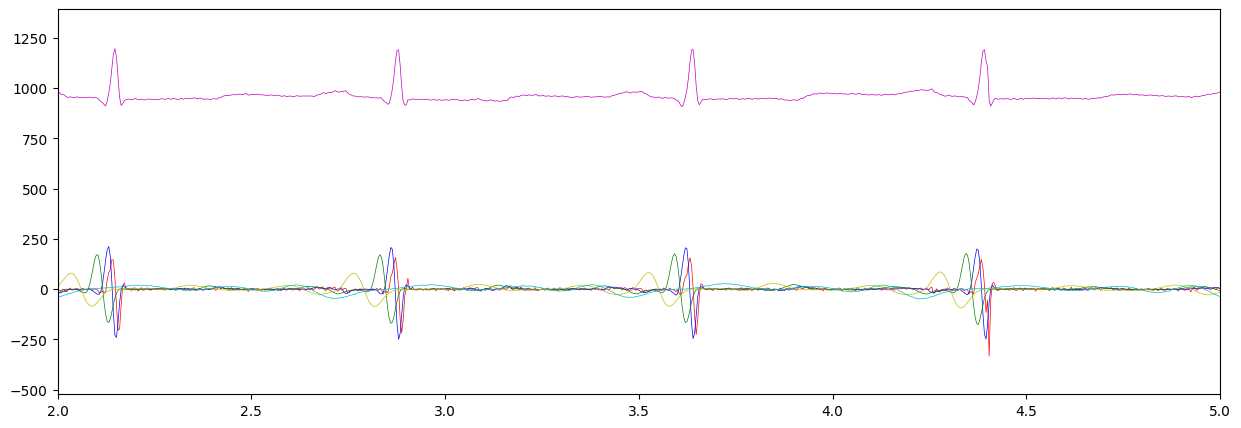

In [159]:
# Create time array
time = np.arange(len(ecg)) / fs

# Plot ECG signal
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(time, ecg, 'm-', linewidth=0.5, label='ECG')
ax.plot(time, details[1], 'r-', linewidth=0.5, label='ECG')
ax.plot(time, details[2], 'b-', linewidth=0.5, label='ECG')
ax.plot(time, details[3], 'g-', linewidth=0.5, label='ECG')
ax.plot(time, details[4], 'y-', linewidth=0.5, label='ECG')
ax.plot(time, details[5], 'c-', linewidth=0.5, label='ECG')
ax.set_xlim(2, 5)

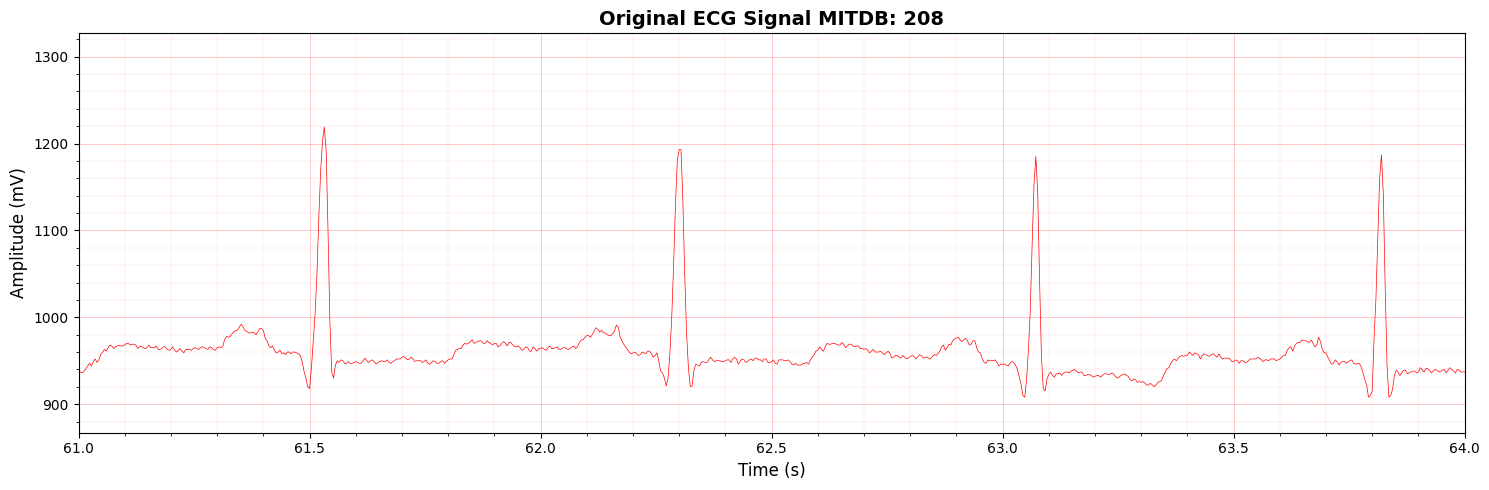

Total duration: 900.0 seconds
Sampling frequency: 250 Hz


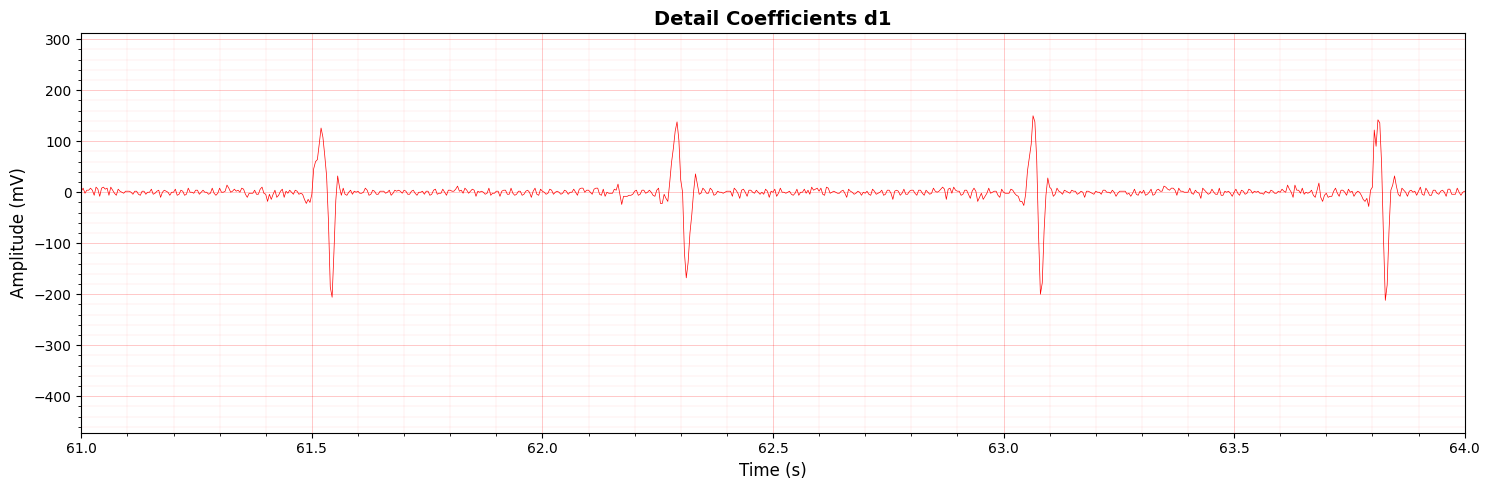

Total duration: 900.0 seconds
Sampling frequency: 250 Hz


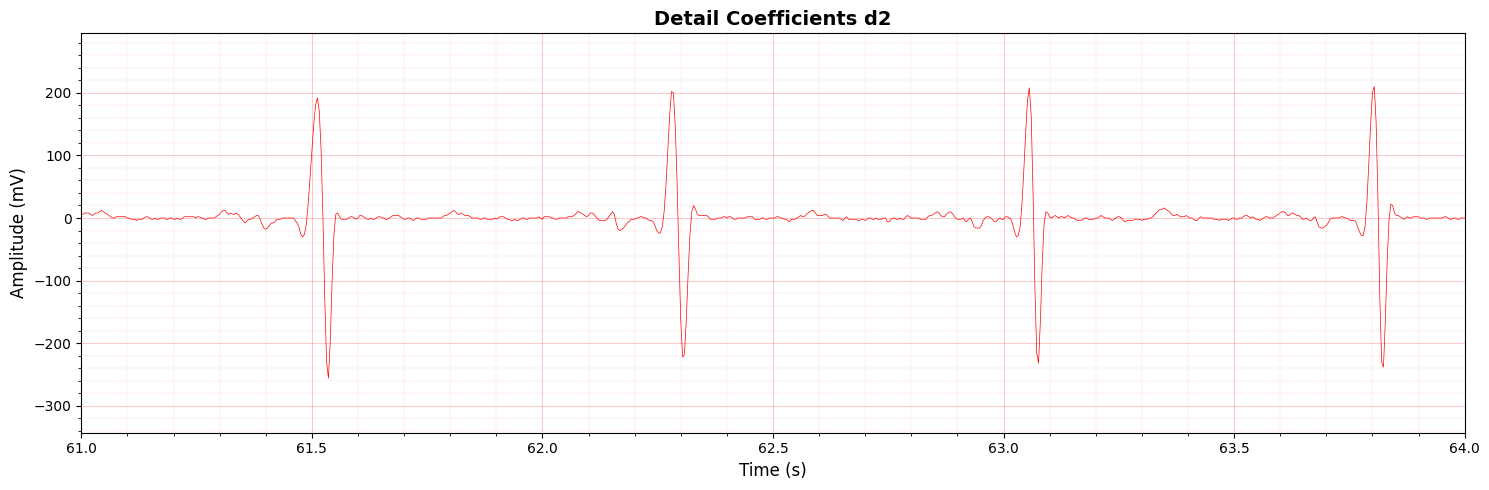

Total duration: 900.0 seconds
Sampling frequency: 250 Hz


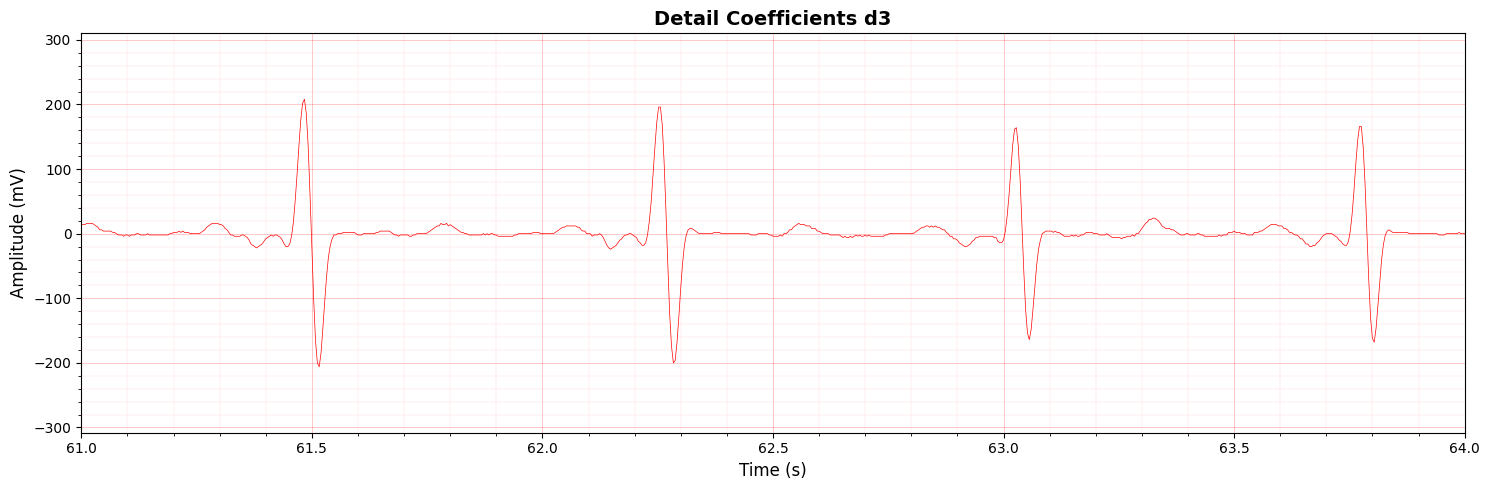

Total duration: 900.0 seconds
Sampling frequency: 250 Hz


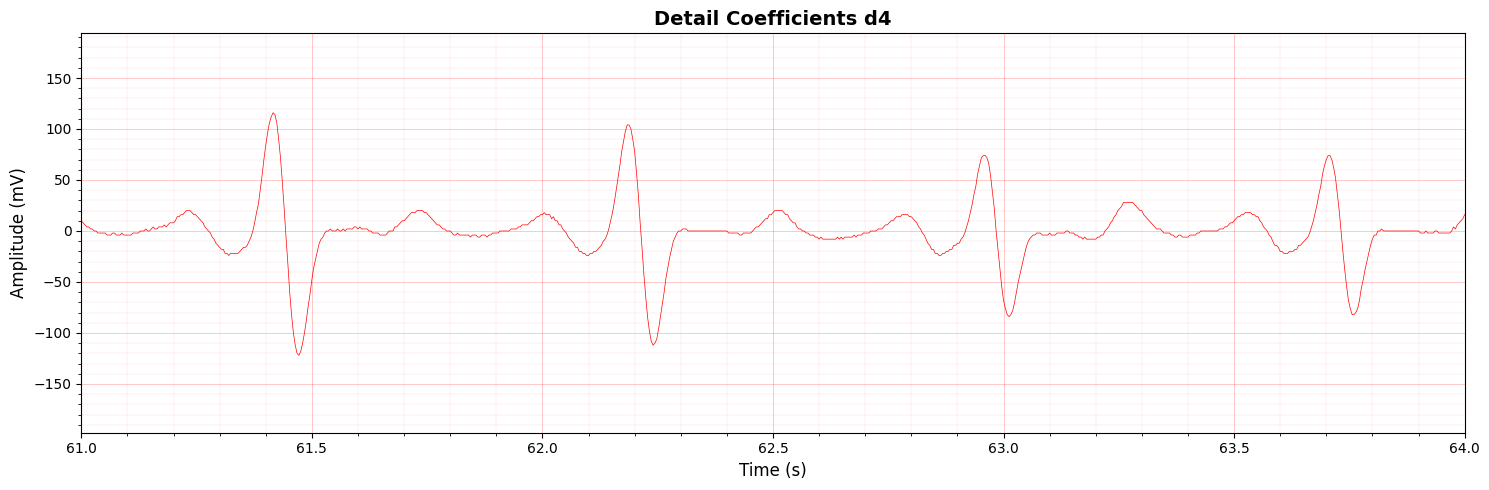

Total duration: 900.0 seconds
Sampling frequency: 250 Hz


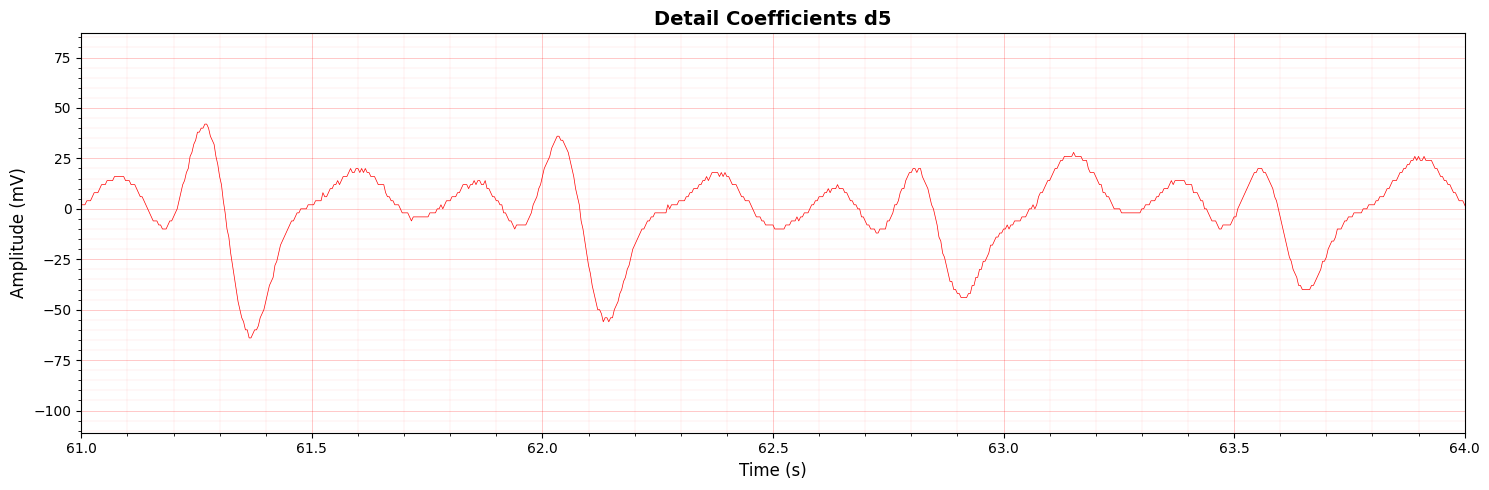

Total duration: 900.0 seconds
Sampling frequency: 250 Hz


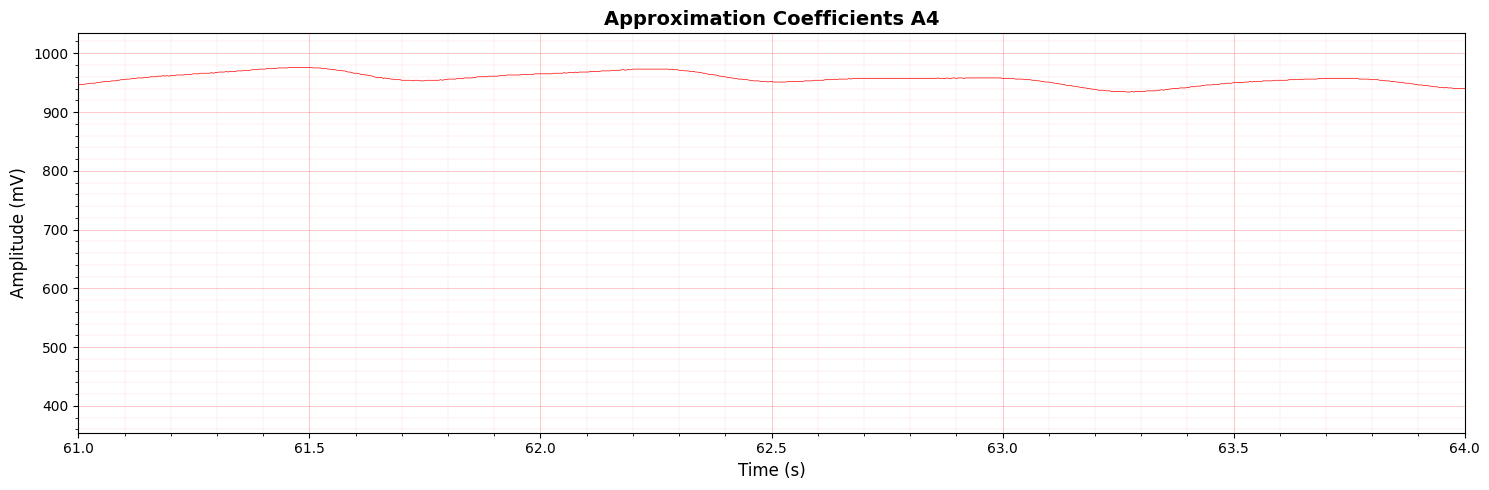

Total duration: 900.0 seconds
Sampling frequency: 250 Hz


In [160]:
time_range = (61, 64)
plot_ecg(ecg, fs, time_range = time_range, title=f'Original ECG Signal MITDB: {mit_bih_records[current]}')
for level in details:
    plot_ecg(details[level], fs, time_range = time_range, title=f'Detail Coefficients d{level}')
plot_ecg(approximation, fs, time_range = time_range, title='Approximation Coefficients A4')

## Online QRS detection and P-QRS-T delineation

###  QRS-complex detection


In [161]:
def max_min_difference(signal):
    '''Calculate the difference between the maximum and minimum value in a vector'''
    max = np.max(signal)
    min = np.min(signal)
    delta = max - min
    return delta

def is_zero_crossing(signal, i):
    '''
    Calculate if two point are a zero-crossing. 
    If they are return the AMMp value, otherwise return 0.
    '''
    # Check if there is a zero crossing between i-1 and i
    if (signal[i-1] <= 0 and signal[i] > 0) or (signal[i-1] > 0 and signal[i] <= 0):
        # search left
        j = i - 1
        loc_max = abs(signal[j])
        while j > 0 and abs(signal[j-1]) >= loc_max:
            j -= 1
            loc_max = abs(signal[j])
        left_peak = abs(signal[j])
        left_peak_pos = j

        # search right
        j = i
        loc_max = abs(signal[j])
        while  j < len(signal)-1 and abs(signal[j+1]) >= loc_max:
            j += 1
            loc_max = abs(signal[j])
        right_peak = abs(signal[j])
        right_peak_pos = j
        # calculate Adjacent Modulus Maxima pair
        AMMp = left_peak + right_peak
    else:
        AMMp = 0
        left_peak_pos = None
        right_peak_pos = None
    return AMMp, left_peak_pos, right_peak_pos

def QRS_detection(details, fs):
    '''
    Docstring for QRS_detection
    
    :param details: detail coefficents from WT
    :param fs: sampling frequency
    '''
    # detail levels used
    d2=details[2]
    d3=details[3]
    qrs_positions = []                  # found qrs postions
    qrs_d2_delta = []                   # qrs min-max delta on d^2
    qrs_d3_delta = []                   # qrs min-max delta on d^3
    qrs_d2_peaks_pos = []               # qrs peak positions on d^2
    qrs_found = 0                       # number of QRS found
    deltaWQRS = np.right_shift(fs, 2)   # observation window = 250 ms
    deltaW100 = int(fs * 0.1)           # half-window samples number for detection rules
    i_zc = int(1)                       # index for zero-crossing search
    signal_length = len(d2)

     # search zero-crossings in detail level 2^2
    while i_zc < signal_length:
        AMMp, left_peak_pos, right_peak_pos = is_zero_crossing(d2, i_zc)   # Adjacent Modulus Maxima pair
        # if zero-crossing (ZCs) is found (AMMp>0) start looking for 
        # better ZCs (bigger AMMp) in the observation window
        if AMMp > 0:
            j_zc = i_zc + 1
            # iterate in the observation window looking for better QRS-candidates
            while j_zc < i_zc + deltaWQRS and j_zc < signal_length:
                AMMp_new, left_peak_pos_new, right_peak_pos_new = is_zero_crossing(d2, j_zc)
                # if a bigger AMMp is found, restart the obs. window
                if AMMp_new > AMMp:
                    AMMp = AMMp_new
                    left_peak_pos = left_peak_pos_new
                    right_peak_pos = right_peak_pos_new
                    i_zc = j_zc # new QRS candidate found
                else:
                    j_zc += 1

            # QRS candidate decision  
            delta_window = max(0, i_zc-deltaW100), min(signal_length-1, i_zc+deltaW100)
            e_start = max(0, qrs_found-4)
            zc_d2_delta = max_min_difference(d2[delta_window[0]:delta_window[1]])
            epsilon_d2 = np.right_shift(11 * sum(qrs_d2_delta[e_start:qrs_found]), 7)
            # first test on d^2
            if zc_d2_delta > epsilon_d2:
                zc_d3_delta = max_min_difference(d3[delta_window[0]:delta_window[1]])
                epsilon_d3 = np.right_shift(11 * sum(qrs_d3_delta[e_start:qrs_found]), 7)
                # second test on d^3
                if zc_d3_delta > epsilon_d3:
                    # QRS-candidate ACCEPTED
                    qrs_positions.append(np.int32(i_zc))
                    qrs_d2_delta.append(zc_d2_delta)
                    qrs_d3_delta.append(zc_d3_delta)
                    qrs_d2_peaks_pos.append((left_peak_pos, right_peak_pos))
                    qrs_found += 1
            i_zc += deltaWQRS + 1
        else:
            i_zc += 1
    #return qrs_positions[4:]
    return qrs_positions, qrs_d2_peaks_pos

r_peaks, qrs_d2_peaks_pos = QRS_detection(details, fs)

In [162]:
r_peaks

[np.int32(14),
 np.int32(142),
 np.int32(345),
 np.int32(536),
 np.int32(718),
 np.int32(908),
 np.int32(1097),
 np.int32(1295),
 np.int32(1500),
 np.int32(1696),
 np.int32(1889),
 np.int32(2077),
 np.int32(2269),
 np.int32(2457),
 np.int32(2643),
 np.int32(2839),
 np.int32(3046),
 np.int32(3238),
 np.int32(3424),
 np.int32(3606),
 np.int32(3781),
 np.int32(3961),
 np.int32(4143),
 np.int32(4325),
 np.int32(4509),
 np.int32(4693),
 np.int32(4883),
 np.int32(5061),
 np.int32(5227),
 np.int32(5397),
 np.int32(5572),
 np.int32(5748),
 np.int32(5927),
 np.int32(6110),
 np.int32(6290),
 np.int32(6461),
 np.int32(6634),
 np.int32(6807),
 np.int32(6980),
 np.int32(7151),
 np.int32(7335),
 np.int32(7523),
 np.int32(7713),
 np.int32(7897),
 np.int32(8078),
 np.int32(8257),
 np.int32(8444),
 np.int32(8630),
 np.int32(8817),
 np.int32(9013),
 np.int32(9207),
 np.int32(9395),
 np.int32(9576),
 np.int32(9752),
 np.int32(9928),
 np.int32(10107),
 np.int32(10299),
 np.int32(10485),
 np.int32(10672),


In [163]:
len(r_peaks), len(annotations.sample)

(1135, 3040)

(60.0, 63.0)

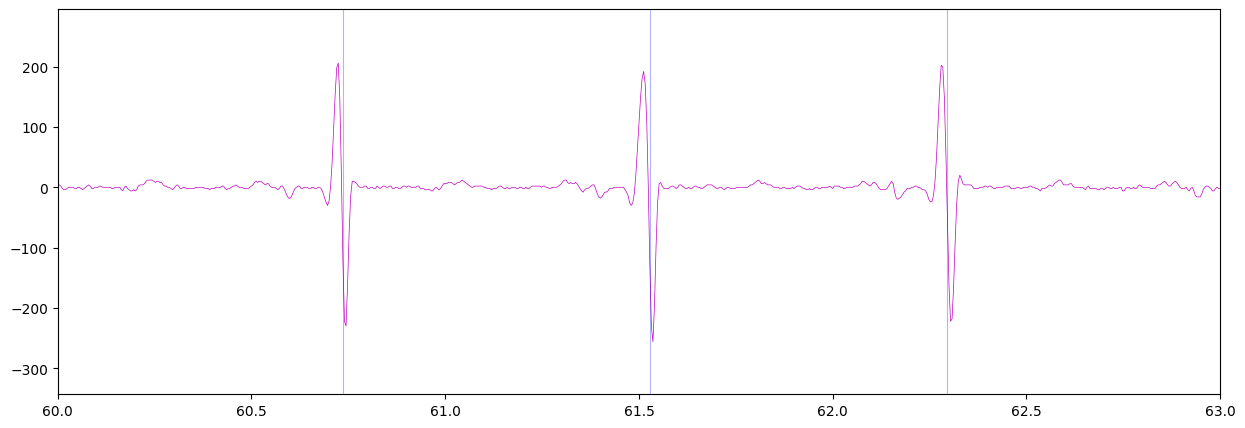

In [164]:
# Create time array
time = np.arange(len(ecg)) / fs

# Plot ECG signal
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(time, details[2], 'm-', linewidth=0.5, label='ECG')
for t in r_peaks:
    ax.axvline(t/fs, color='blue', alpha=0.3, linewidth=0.8)
ax.set_xlim(60, 63)

###  QRS-complex delineation (offset/offset)

In [165]:
def is_local_max(signal, i):
    if i <= 0 or i >= len(signal) - 1:
        return False
    val = abs(signal[i])
    return val > abs(signal[i-1]) and val >= abs(signal[i+1])

def QRS_delineation(details, fs, r_peaks, qrs_d2_peaks_pos):
    d2 = details[2]
    fixed_window = fs * 0.120  # 120 ms fixed window
    QRS_on = []
    QRS_off = []

    for key, qrs_pos in enumerate(r_peaks):
        npre = qrs_d2_peaks_pos[key][0]
        npost = qrs_d2_peaks_pos[key][1]

        d2_npre = int(abs(d2[npre]))
        d2_npost = int(abs(d2[npost]))
        
        # onset search
        e1_onset = np.right_shift(d2_npre + d2_npost, 5) # divide by 32 using bit-shift
        e2_onset = np.right_shift(d2_npre + d2_npost, 4) # divide by 16 using bit-shift
        
        i = npre
        search_e1 = True          # search for e1 crossing
        search_onset = True       # search for onset
        
        onset = None
        candidate_onset = None
        n_left = None

        window_end = max(0, i - fixed_window)
        while search_onset and i > window_end:
            mod_d2i = abs(d2[i])

            if search_e1 and mod_d2i <= e1_onset:
                candidate_onset = i
                search_e1 = False

            if is_local_max(d2, i):
                if mod_d2i <= e2_onset:
                    n_left = i
                    search_onset = False
                else:
                    n_left = i
            i -= 1

        if n_left is None:
            if candidate_onset is not None:
                onset = candidate_onset
            else:
                onset = window_end

        # if onset not found, search for e3 crossing
        if onset is None:
            e3_onset = np.right_shift(abs(int(d2[n_left])), 2) # divide by 4 using bit-shift
            i = n_left
            while onset is None and i > window_end:
                mod_d2i = abs(d2[i])
                if mod_d2i < e3_onset:
                    onset = i
                i -= 1
            onset = window_end if i <= window_end else onset

        QRS_on.append(np.int32(onset))
        #print(f'QRS at {qrs_pos/fs:.3f} s: onset at {(onset-qrs_pos)/fs:.3f} s')

        # offset search
        e1_offset = np.right_shift(d2_npost, 2) # divide by 4 using bit-shift
        e2_offset = np.right_shift(d2_npost, 3) # divide by 8 using bit-shift
        
        i = npost
        search_e1 = True          # search for e1 crossing
        search_offset = True       # search for offset
        
        offset = None
        candidate_offset = None
        n_right = None

        window_end = min(len(d2) - 1, i + fixed_window)
        while search_offset and i < window_end:
            mod_d2i = abs(d2[i])

            if search_e1 and mod_d2i <= e1_offset:
                candidate_offset = i
                search_e1 = False

            if is_local_max(d2, i):
                if mod_d2i <= e2_offset:
                    n_right = i
                    search_offset = False
                else:
                    n_right = i
            i += 1

        if n_right is None:
            if candidate_offset is not None:
                offset = candidate_offset
            else:
                offset = window_end

        # if offset not found, search for e3 crossing
        if offset is None:
            e3_offset = np.right_shift(abs(int(d2[n_right])), 2) # divide by 4 using bit-shift
            i = n_right
            while offset is None and i < window_end:
                mod_d2i = abs(d2[i])
                if mod_d2i < e3_offset:
                    offset = i
                i += 1
            offset = window_end if i >= window_end else offset

        #print(f'QRS at {qrs_pos/fs:.3f} s: offset at {(offset-qrs_pos)/fs:.3f} s')
        QRS_off.append(np.int32(offset))

    return QRS_on, QRS_off

QRS_onset, QRS_offset = QRS_delineation(details, fs, r_peaks, qrs_d2_peaks_pos)

In [166]:
qrs_events={'onset': QRS_onset, 'offset': QRS_offset, 'peak': r_peaks}
qrs_events

{'onset': [np.int32(0),
  np.int32(128),
  np.int32(331),
  np.int32(522),
  np.int32(705),
  np.int32(875),
  np.int32(1083),
  np.int32(1281),
  np.int32(1486),
  np.int32(1681),
  np.int32(1871),
  np.int32(2044),
  np.int32(2256),
  np.int32(2444),
  np.int32(2629),
  np.int32(2815),
  np.int32(3031),
  np.int32(3224),
  np.int32(3410),
  np.int32(3593),
  np.int32(3769),
  np.int32(3946),
  np.int32(4130),
  np.int32(4310),
  np.int32(4496),
  np.int32(4677),
  np.int32(4866),
  np.int32(5045),
  np.int32(5213),
  np.int32(5383),
  np.int32(5558),
  np.int32(5734),
  np.int32(5913),
  np.int32(6096),
  np.int32(6275),
  np.int32(6447),
  np.int32(6620),
  np.int32(6792),
  np.int32(6965),
  np.int32(7125),
  np.int32(7321),
  np.int32(7508),
  np.int32(7698),
  np.int32(7883),
  np.int32(8066),
  np.int32(8243),
  np.int32(8431),
  np.int32(8617),
  np.int32(8784),
  np.int32(8988),
  np.int32(9194),
  np.int32(9380),
  np.int32(9563),
  np.int32(9739),
  np.int32(9895),
  np.int3

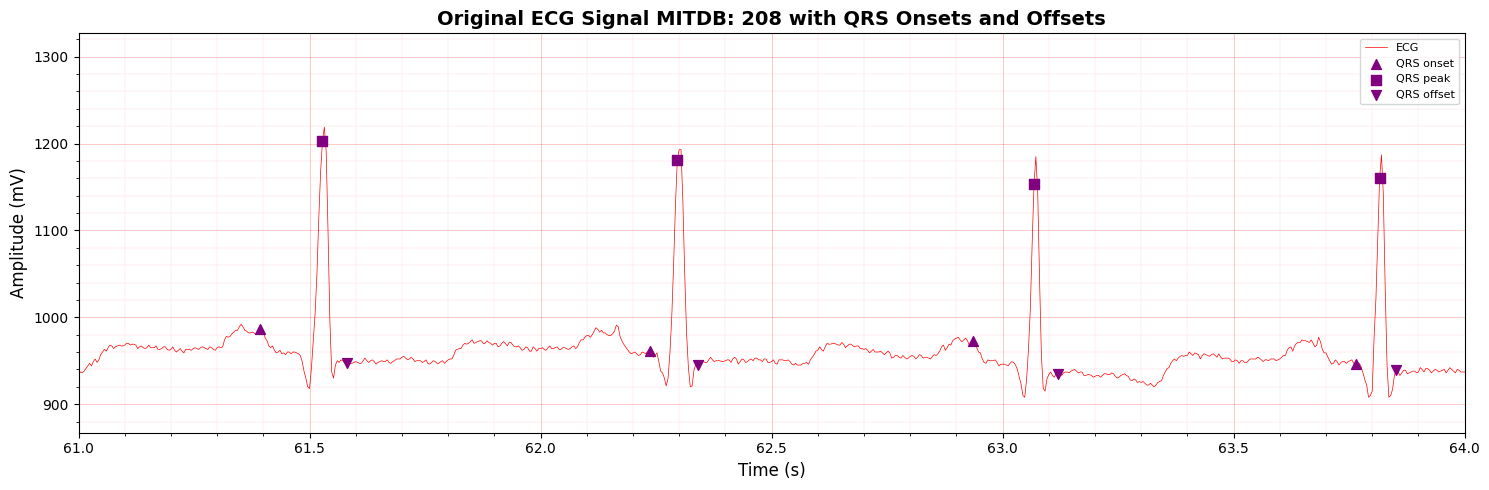

Total duration: 900.0 seconds
Sampling frequency: 250 Hz


In [167]:
plot_ecg(ecg, fs, time_range = time_range, qrs_events=qrs_events, title=f'Original ECG Signal MITDB: {mit_bih_records[current]} with QRS Onsets and Offsets')



### P wave delineation (mono & biphasic)

DEBUG: Failed to find P-wave for QRS at 875


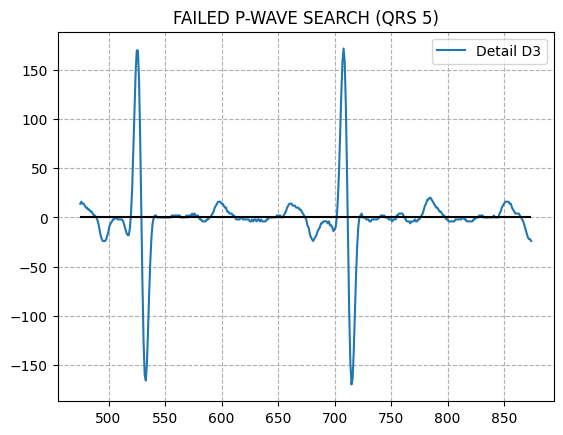

DEBUG: Failed to find P-wave for QRS at 8784


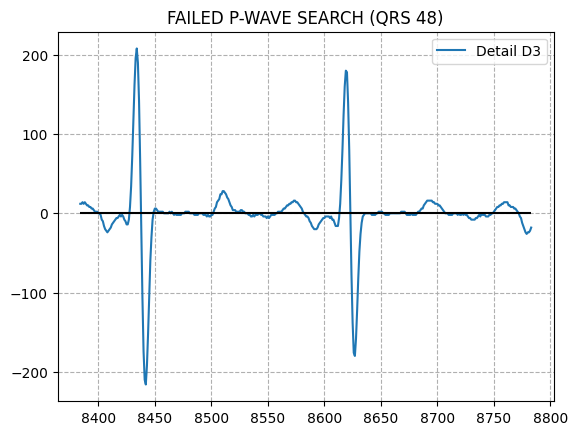

DEBUG: Failed to find P-wave for QRS at 9895


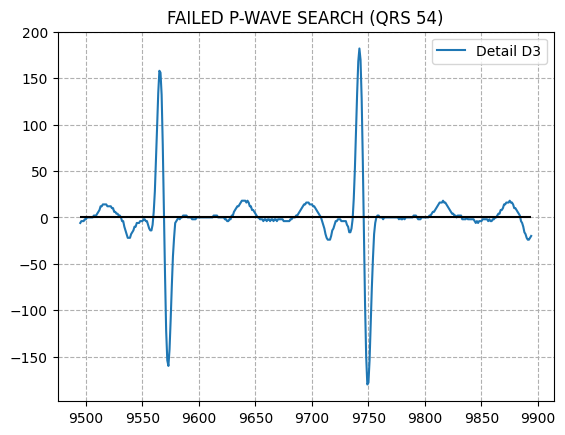

DEBUG: Failed to find P-wave for QRS at 10265


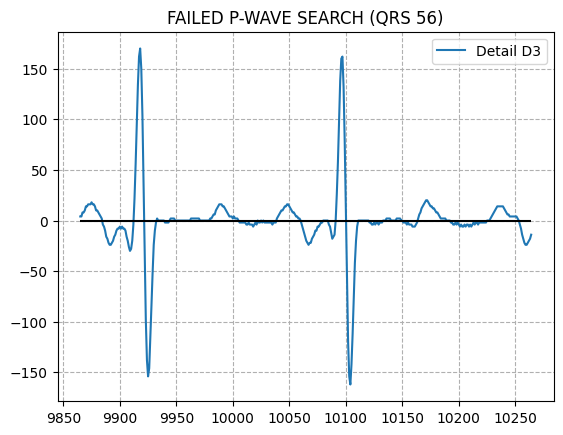

DEBUG: Failed to find P-wave for QRS at 10827


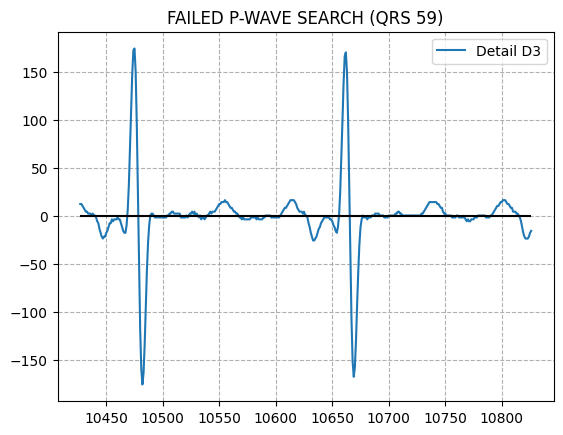

DEBUG: Failed to find P-wave for QRS at 11383


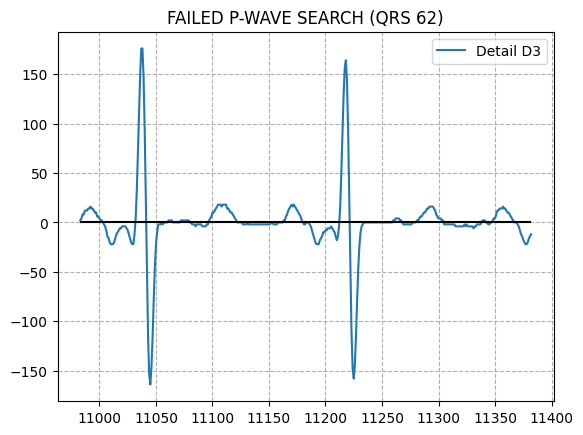

DEBUG: Failed to find P-wave for QRS at 15734


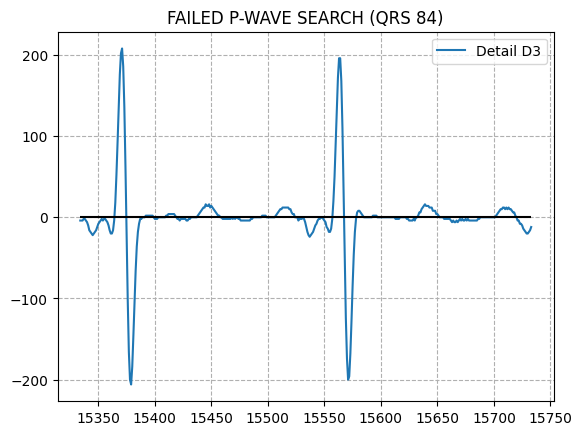

DEBUG: Failed to find P-wave for QRS at 24830


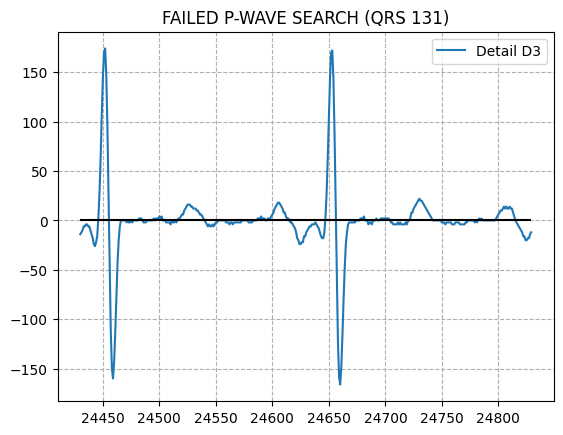

DEBUG: Failed to find P-wave for QRS at 27878


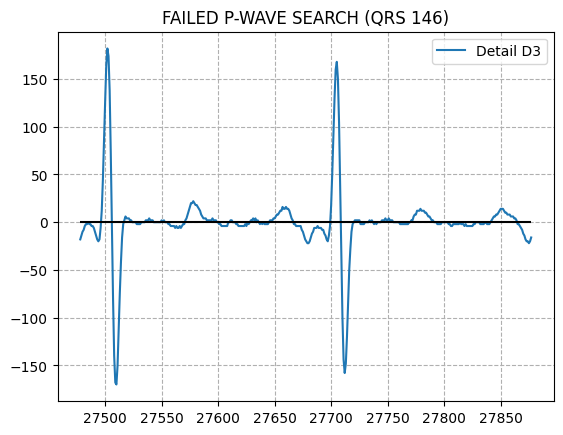

DEBUG: Failed to find P-wave for QRS at 30678


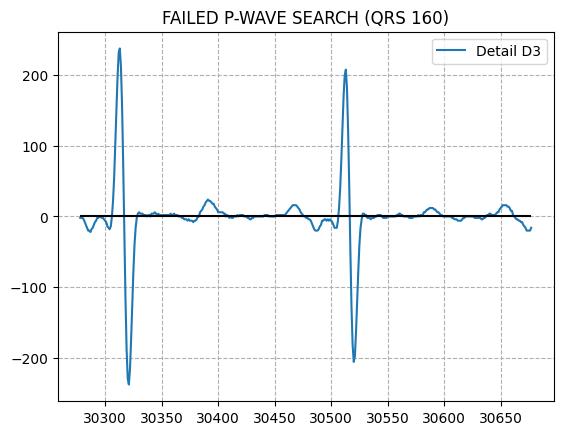

DEBUG: Failed to find P-wave for QRS at 38032


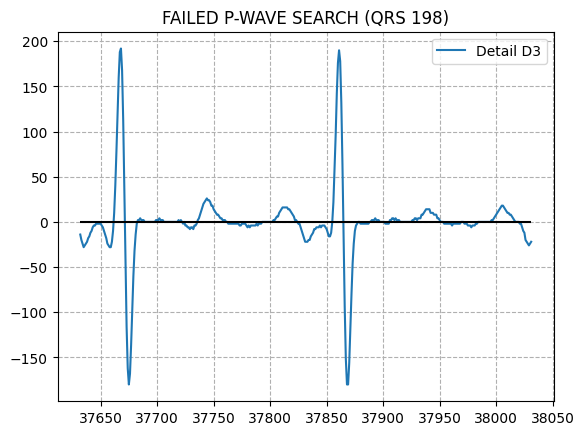

DEBUG: Failed to find P-wave for QRS at 38607


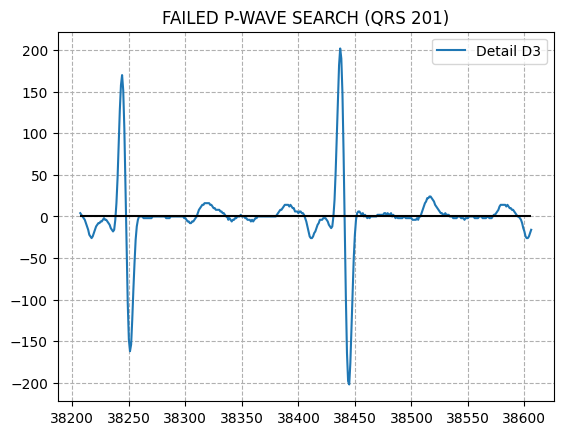

DEBUG: Failed to find P-wave for QRS at 41746


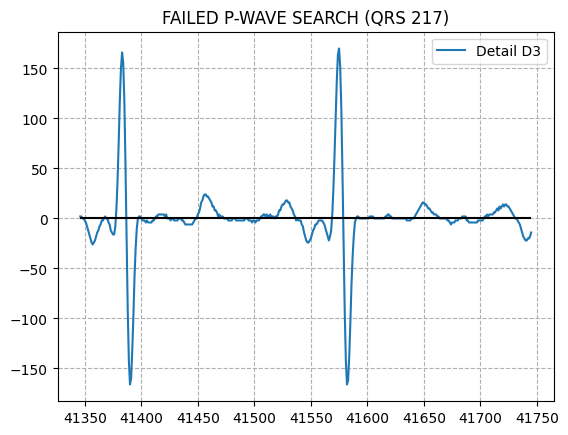

DEBUG: Failed to find P-wave for QRS at 42346


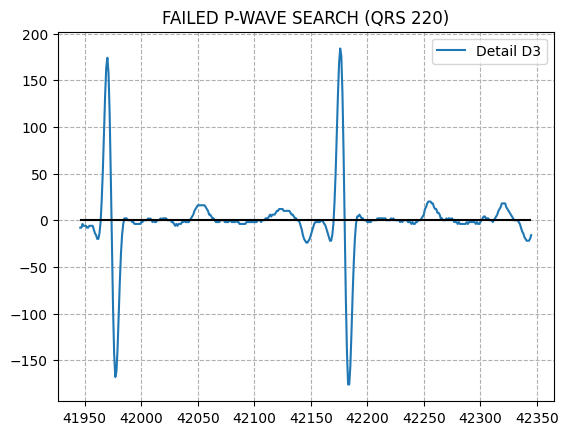

DEBUG: Failed to find P-wave for QRS at 42922


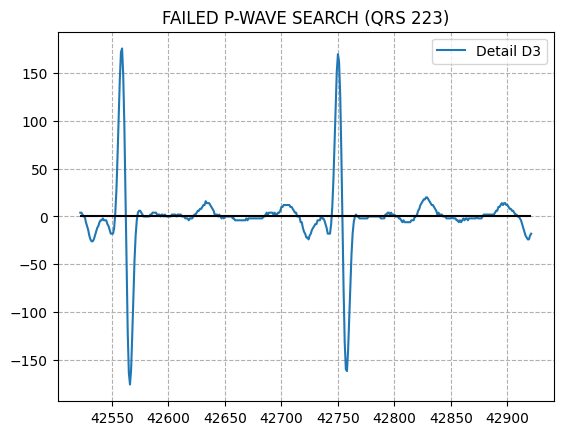

DEBUG: Failed to find P-wave for QRS at 46232


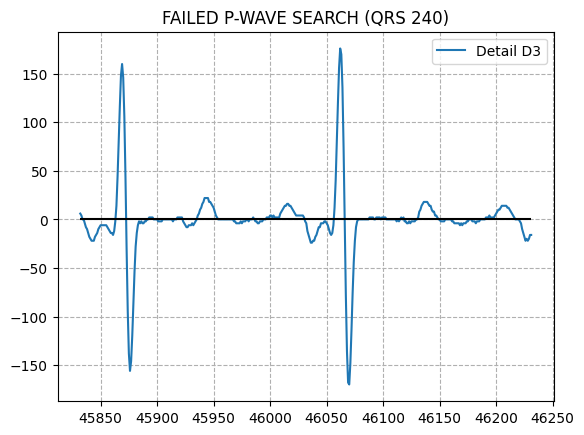

DEBUG: Failed to find P-wave for QRS at 47220


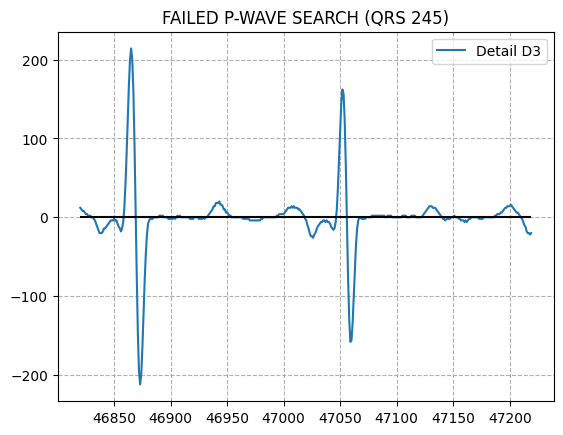

DEBUG: Failed to find P-wave for QRS at 49793


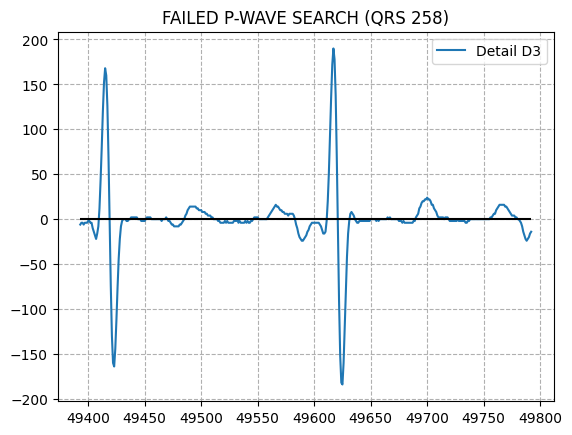

DEBUG: Failed to find P-wave for QRS at 52319


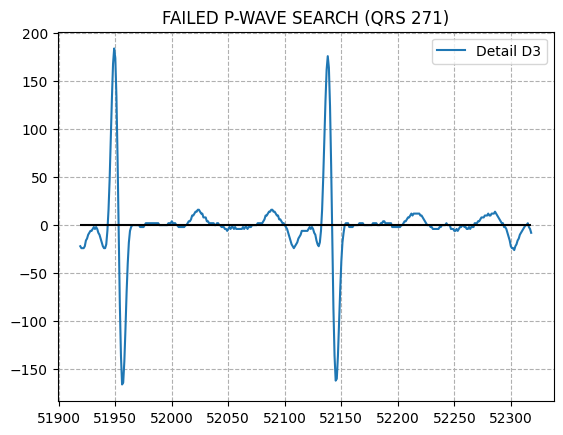

DEBUG: Failed to find P-wave for QRS at 54451


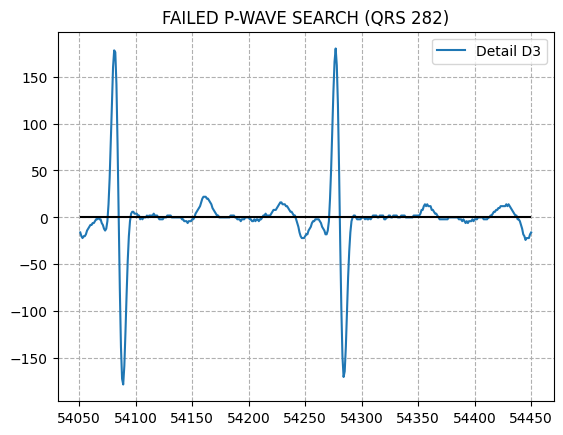

DEBUG: Failed to find P-wave for QRS at 54836


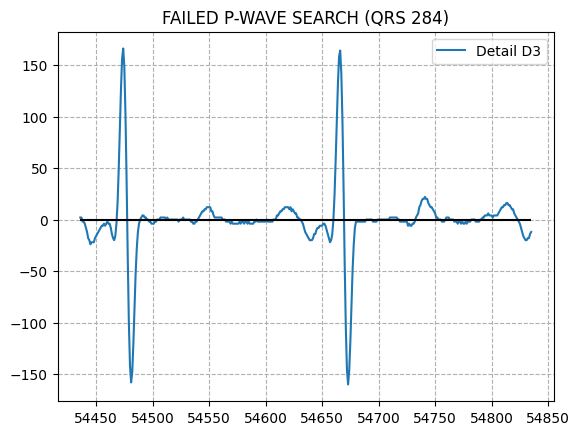

DEBUG: Failed to find P-wave for QRS at 56584


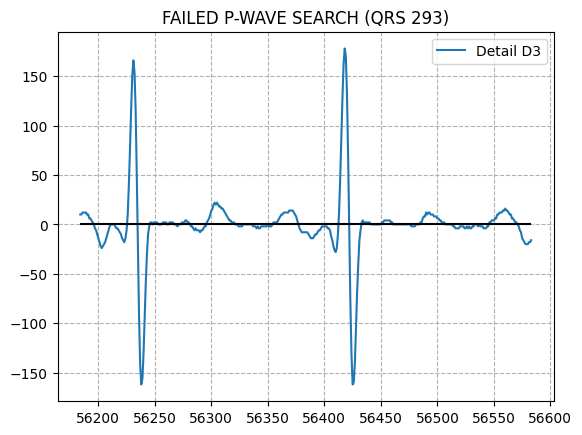

DEBUG: Failed to find P-wave for QRS at 59498


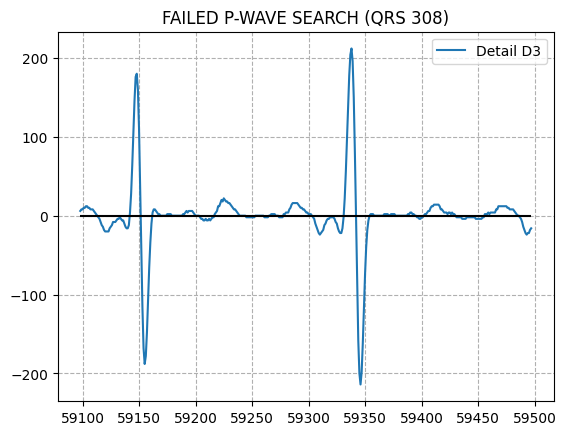

DEBUG: Failed to find P-wave for QRS at 65275


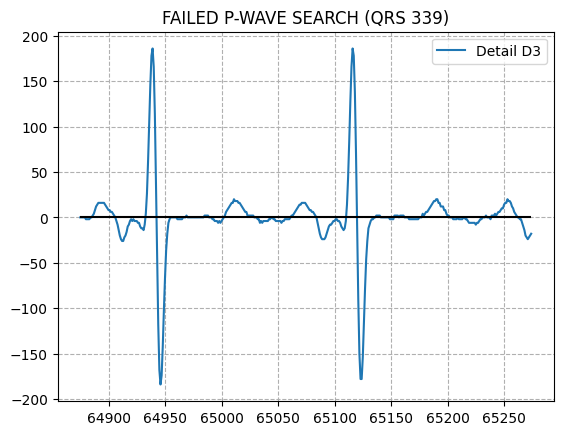

DEBUG: Failed to find P-wave for QRS at 65462


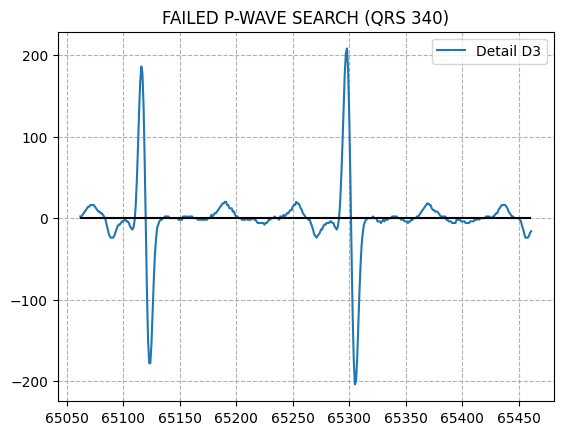

DEBUG: Failed to find P-wave for QRS at 69577


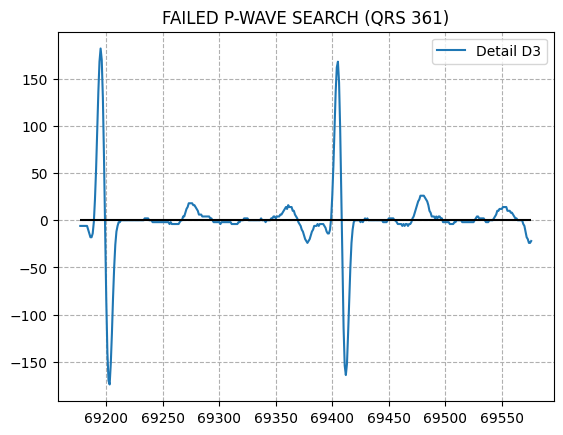

DEBUG: Failed to find P-wave for QRS at 69764


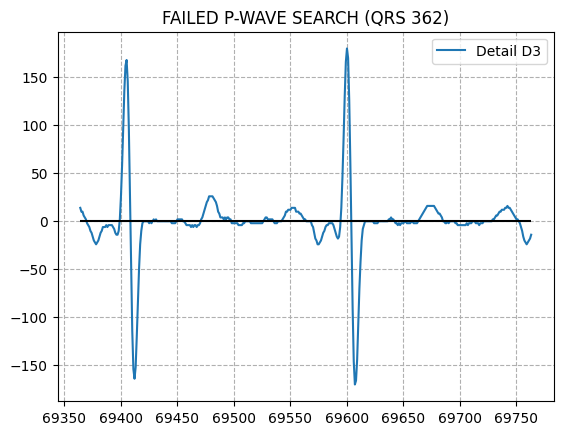

DEBUG: Failed to find P-wave for QRS at 69961


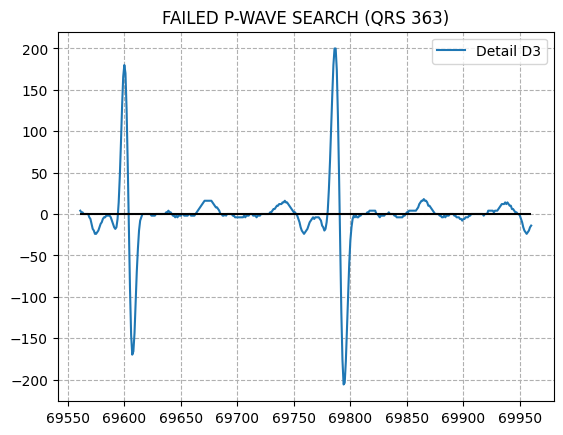

DEBUG: Failed to find P-wave for QRS at 71550


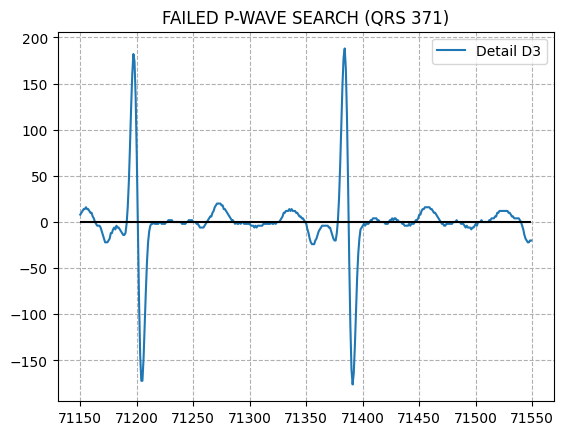

DEBUG: Failed to find P-wave for QRS at 75927


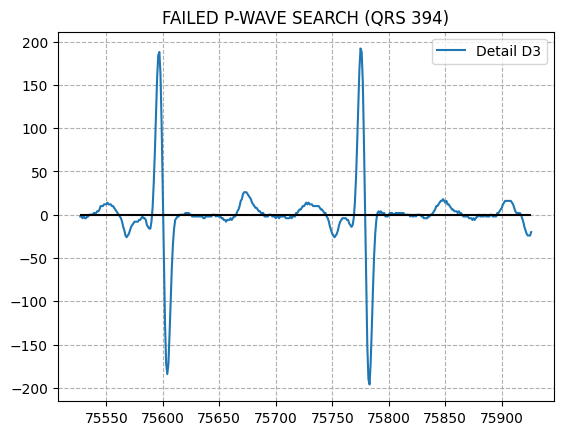

DEBUG: Failed to find P-wave for QRS at 77268


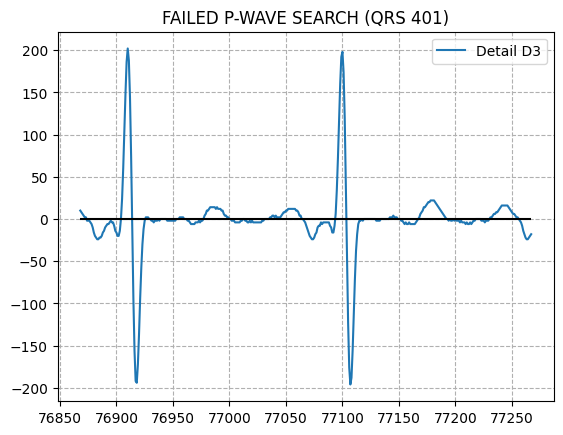

DEBUG: Failed to find P-wave for QRS at 77647


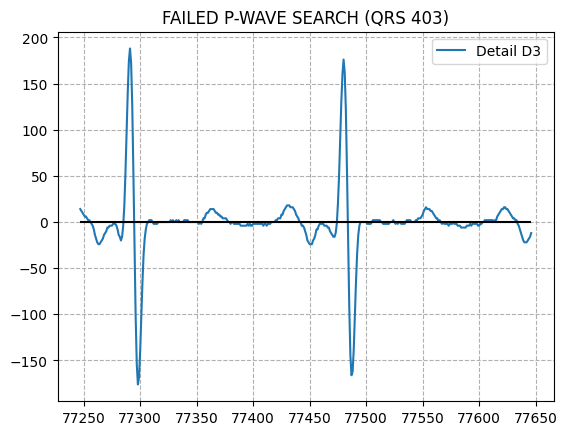

DEBUG: Failed to find P-wave for QRS at 81257


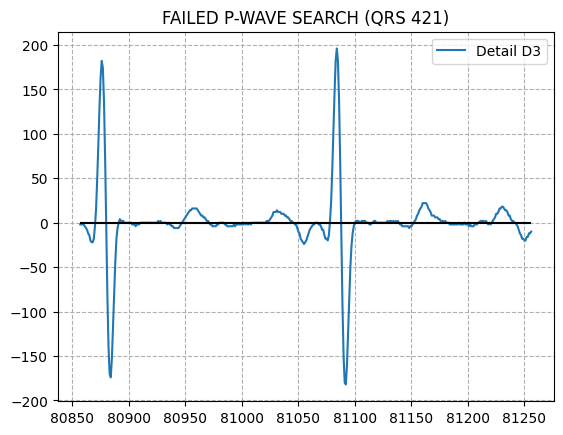

DEBUG: Failed to find P-wave for QRS at 82037


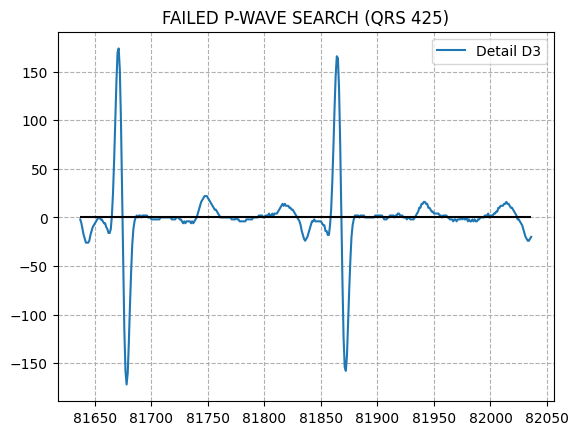

DEBUG: Failed to find P-wave for QRS at 82236


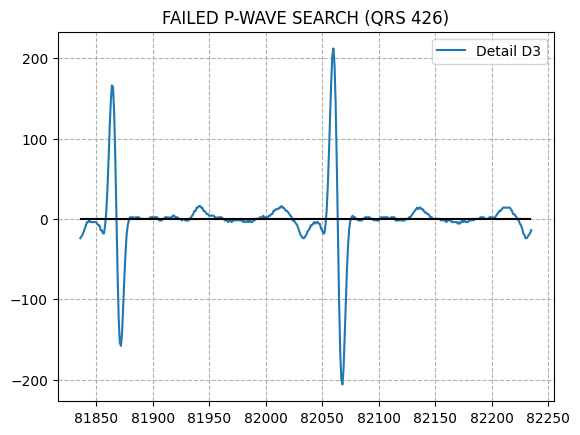

DEBUG: Failed to find P-wave for QRS at 83225


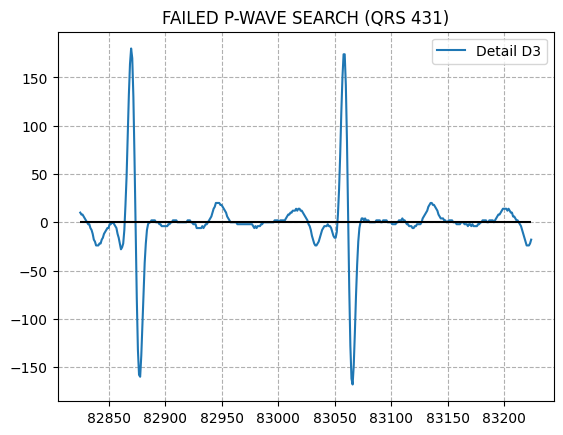

DEBUG: Failed to find P-wave for QRS at 86029


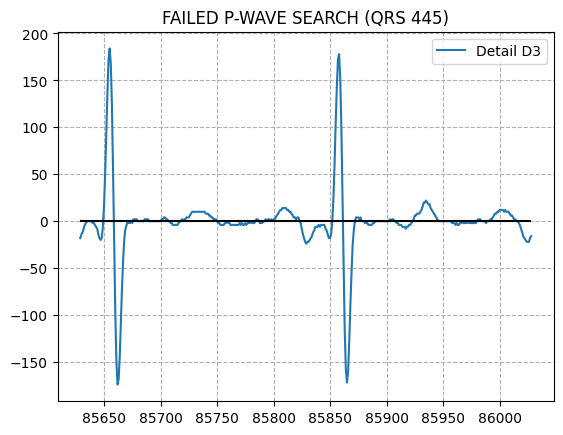

DEBUG: Failed to find P-wave for QRS at 88168


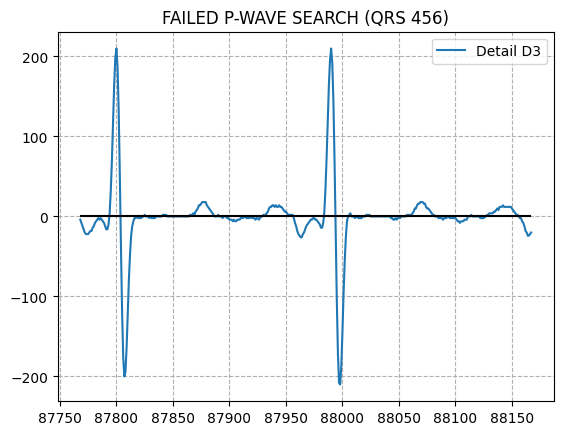

DEBUG: Failed to find P-wave for QRS at 89982


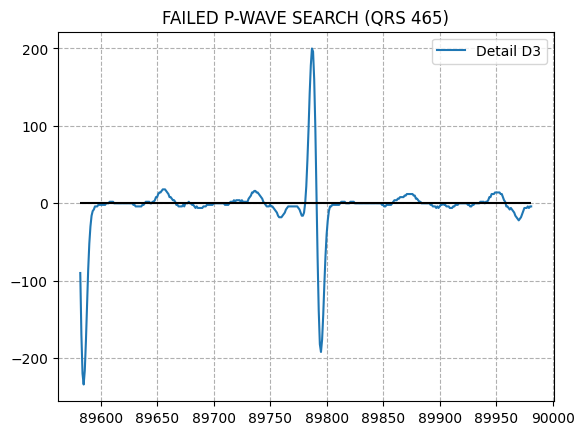

DEBUG: Failed to find P-wave for QRS at 90967


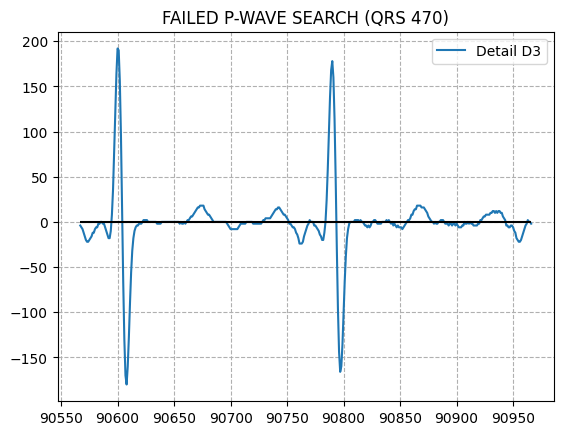

DEBUG: Failed to find P-wave for QRS at 103334


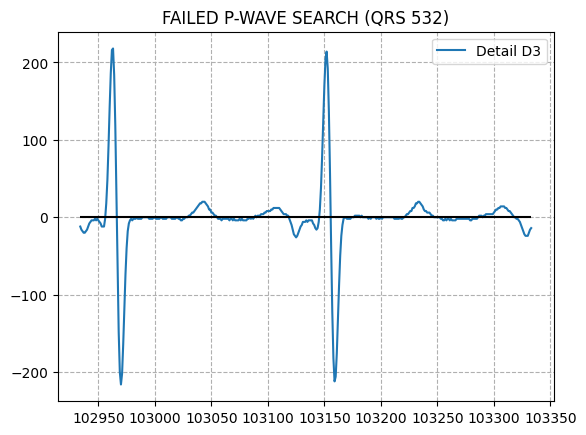

DEBUG: Failed to find P-wave for QRS at 106917


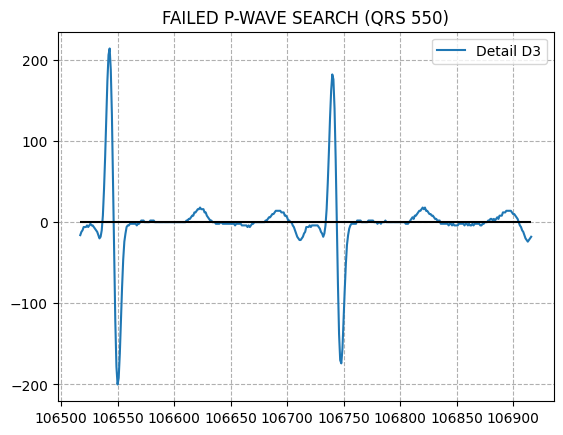

DEBUG: Failed to find P-wave for QRS at 107116


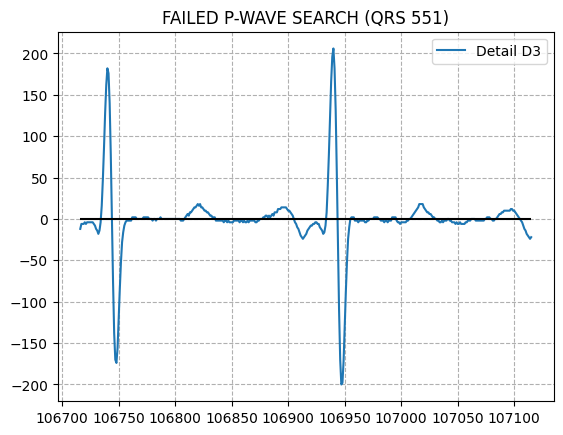

DEBUG: Failed to find P-wave for QRS at 108516


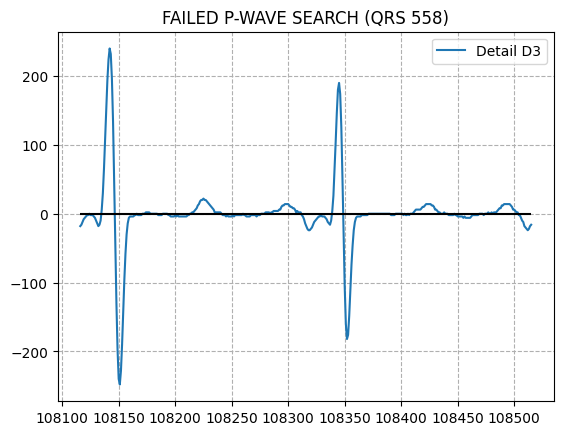

DEBUG: Failed to find P-wave for QRS at 112461


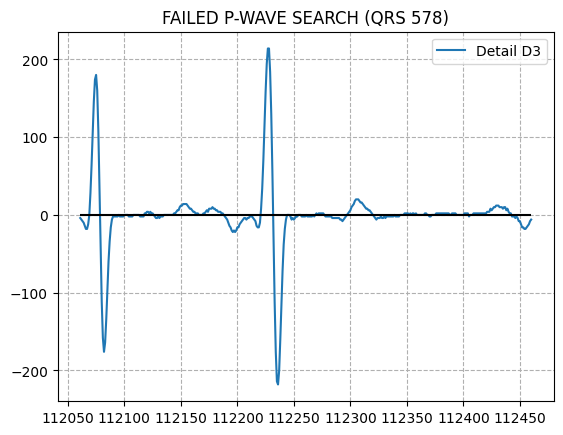

DEBUG: Failed to find P-wave for QRS at 116501


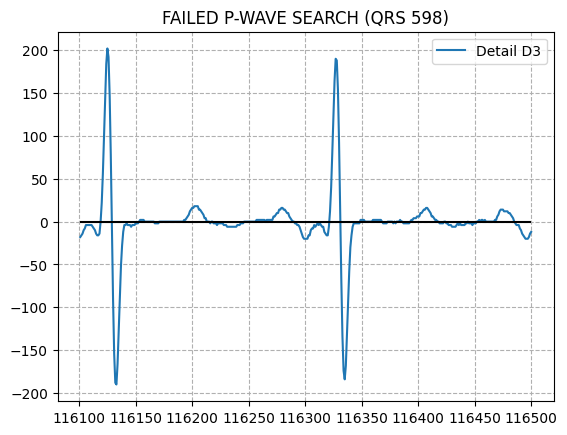

DEBUG: Failed to find P-wave for QRS at 118343


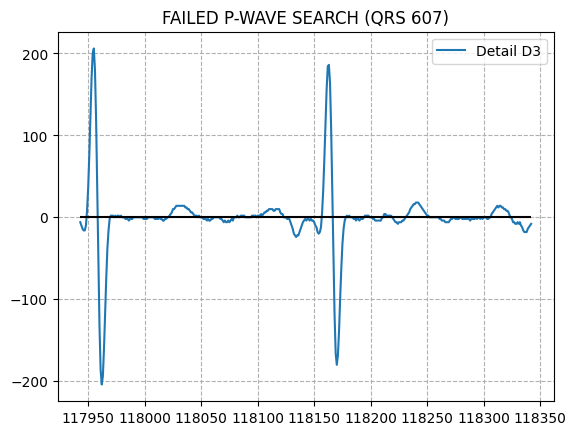

DEBUG: Failed to find P-wave for QRS at 118767


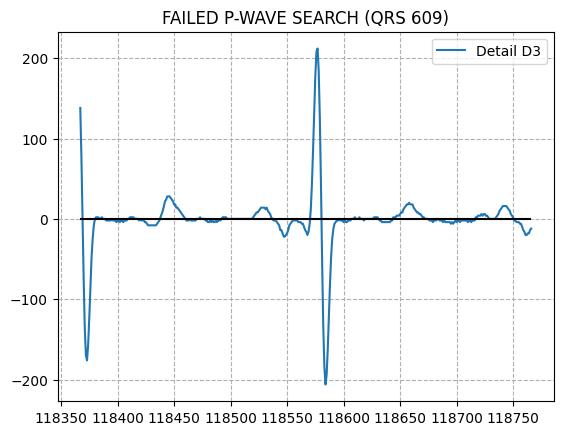

DEBUG: Failed to find P-wave for QRS at 120809


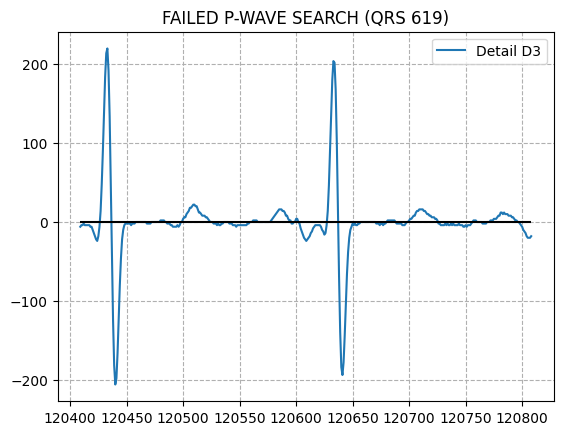

DEBUG: Failed to find P-wave for QRS at 125315


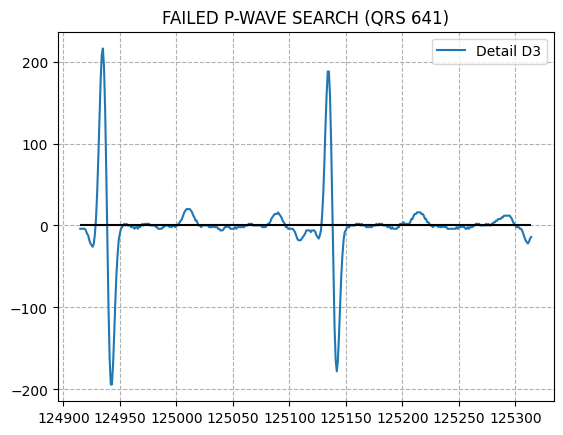

DEBUG: Failed to find P-wave for QRS at 126353


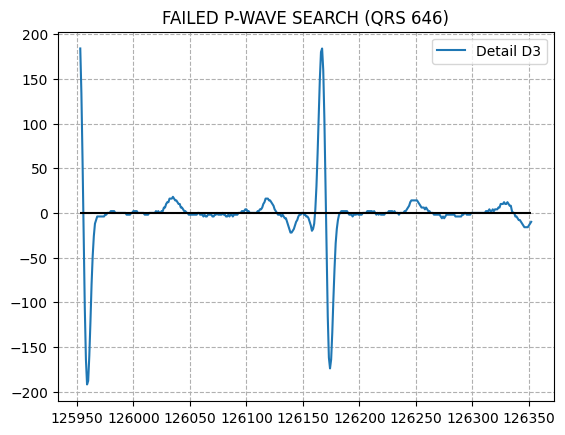

DEBUG: Failed to find P-wave for QRS at 127158


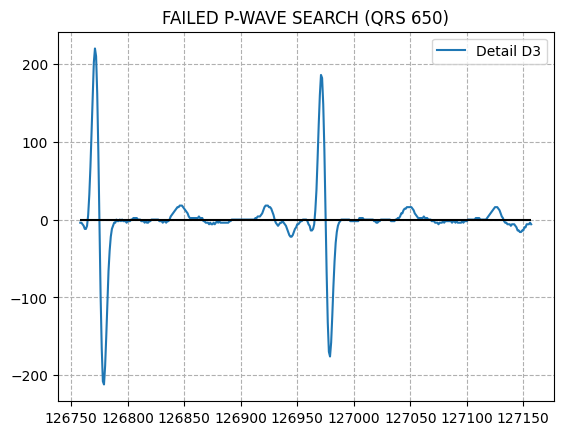

DEBUG: Failed to find P-wave for QRS at 131417


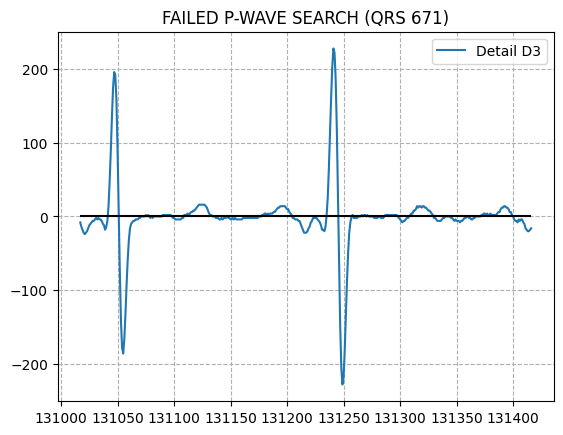

DEBUG: Failed to find P-wave for QRS at 132246


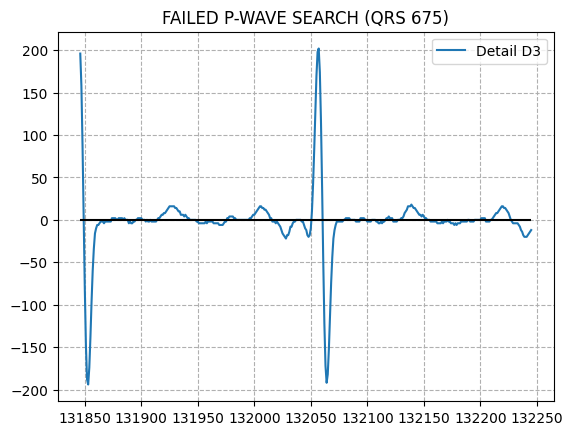

DEBUG: Failed to find P-wave for QRS at 133850


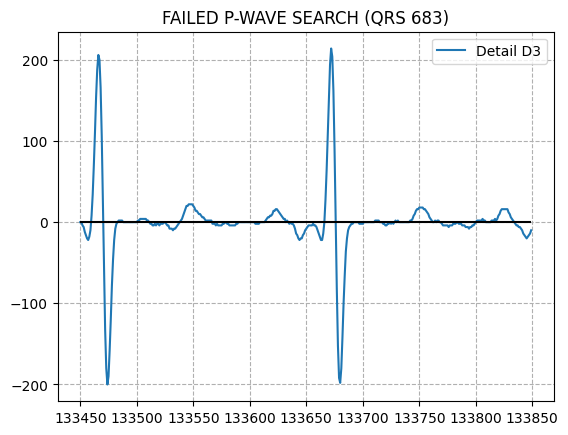

DEBUG: Failed to find P-wave for QRS at 134047


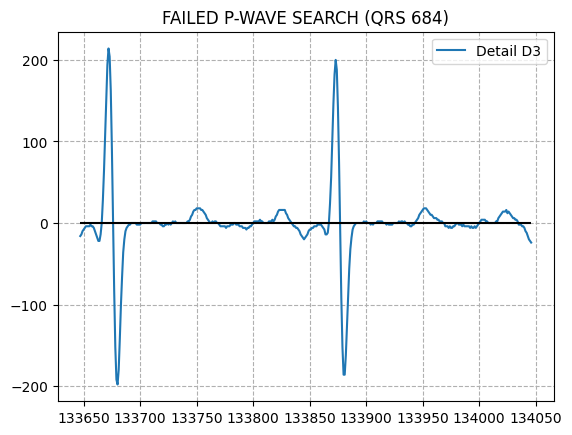

DEBUG: Failed to find P-wave for QRS at 135801


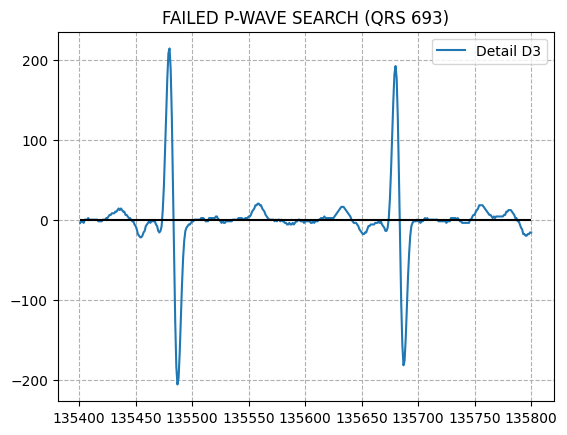

DEBUG: Failed to find P-wave for QRS at 137480


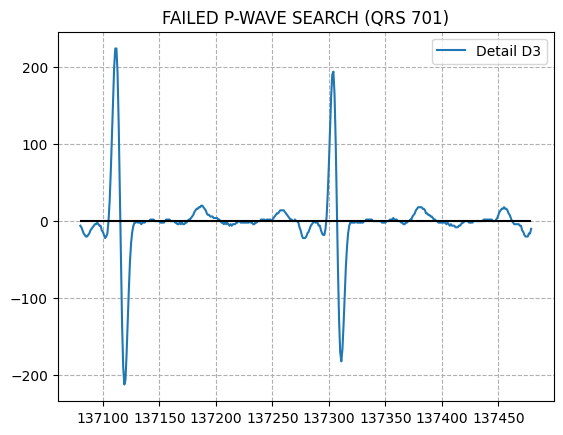

DEBUG: Failed to find P-wave for QRS at 150078


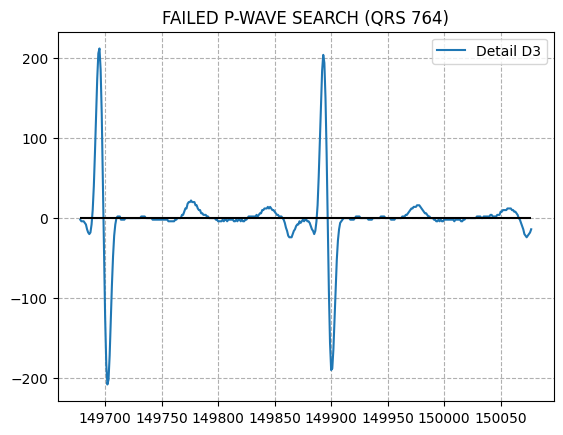

DEBUG: Failed to find P-wave for QRS at 151711


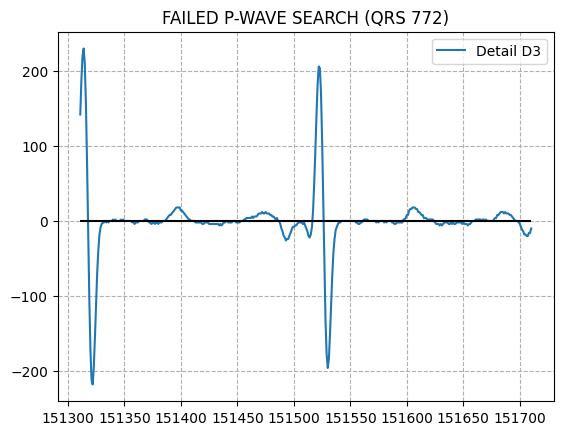

DEBUG: Failed to find P-wave for QRS at 154079


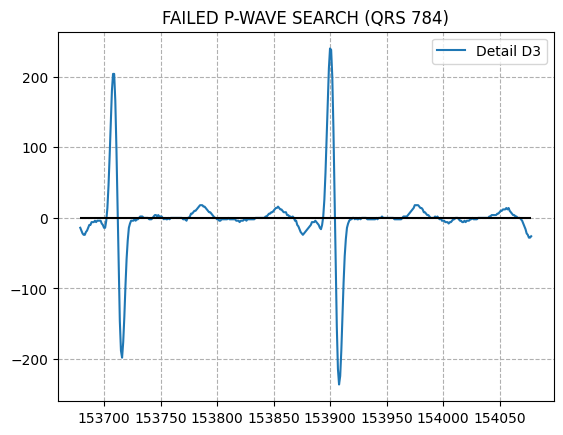

DEBUG: Failed to find P-wave for QRS at 155668


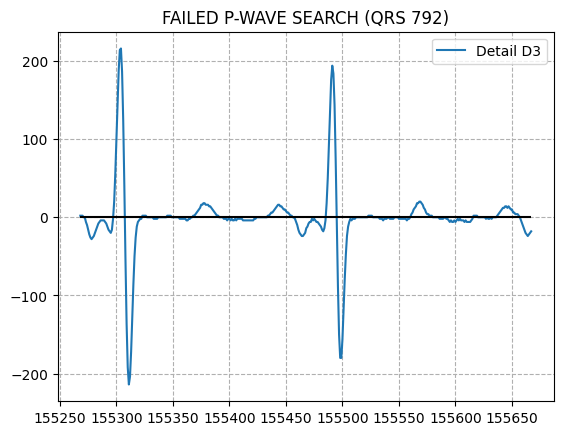

DEBUG: Failed to find P-wave for QRS at 160457


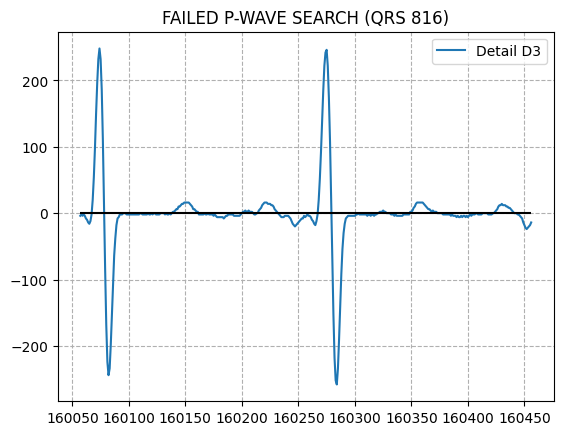

DEBUG: Failed to find P-wave for QRS at 165297


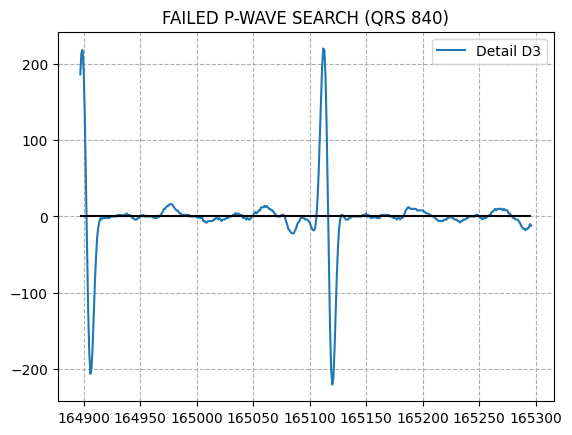

DEBUG: Failed to find P-wave for QRS at 165902


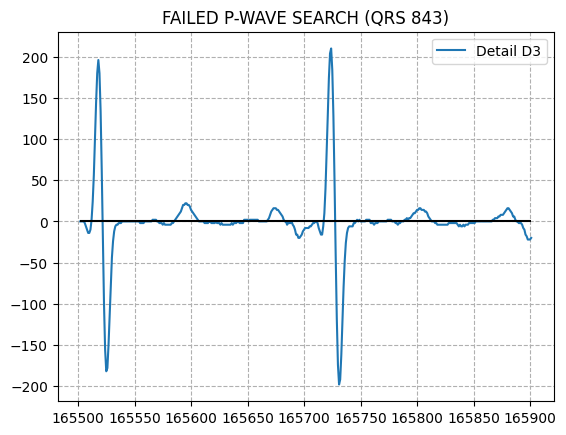

DEBUG: Failed to find P-wave for QRS at 169132


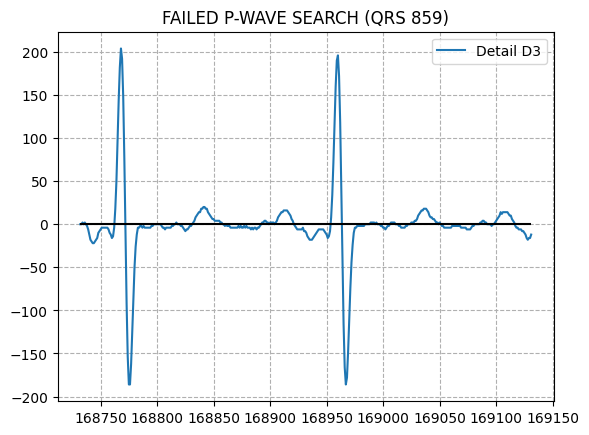

DEBUG: Failed to find P-wave for QRS at 169957


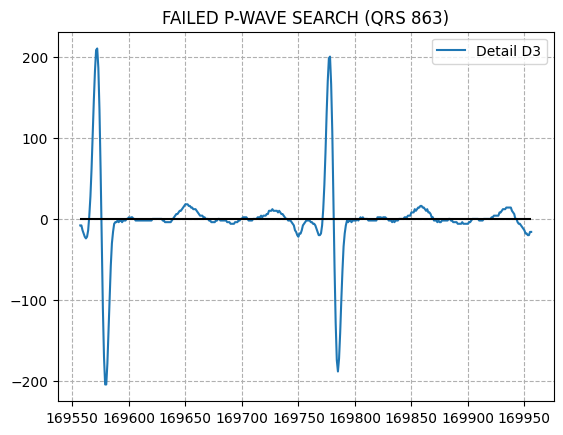

DEBUG: Failed to find P-wave for QRS at 171558


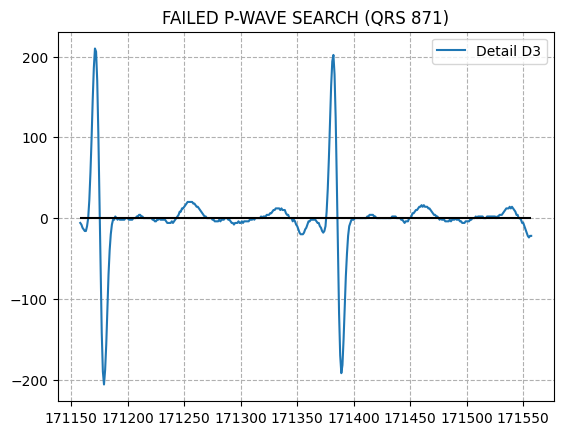

DEBUG: Failed to find P-wave for QRS at 176392


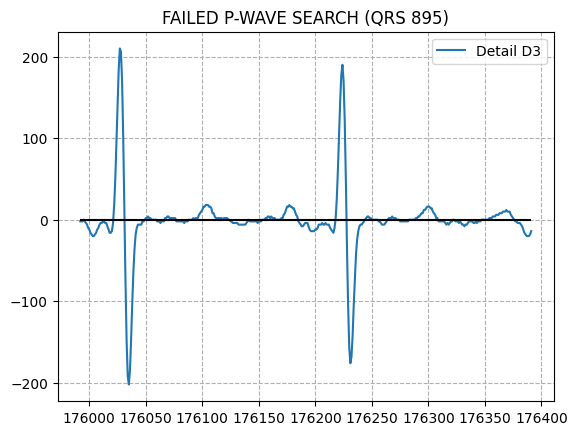

DEBUG: Failed to find P-wave for QRS at 176592


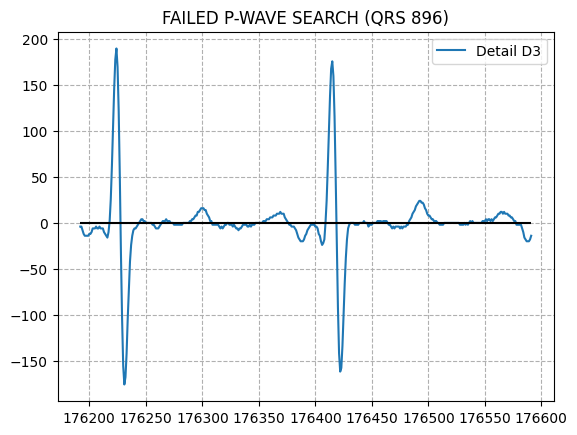

DEBUG: Failed to find P-wave for QRS at 177000


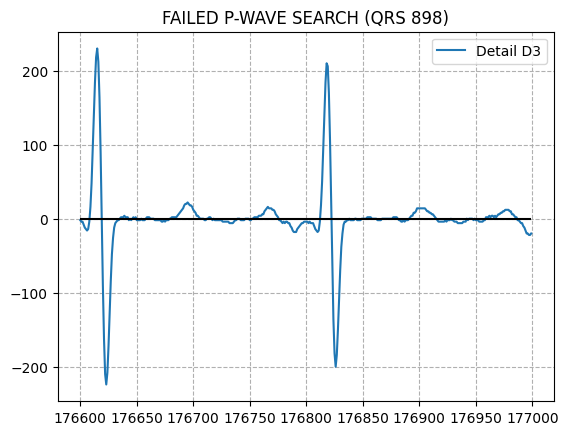

DEBUG: Failed to find P-wave for QRS at 177222


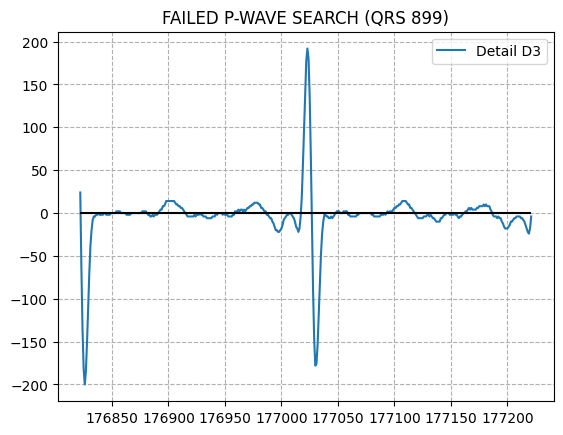

DEBUG: Failed to find P-wave for QRS at 177805


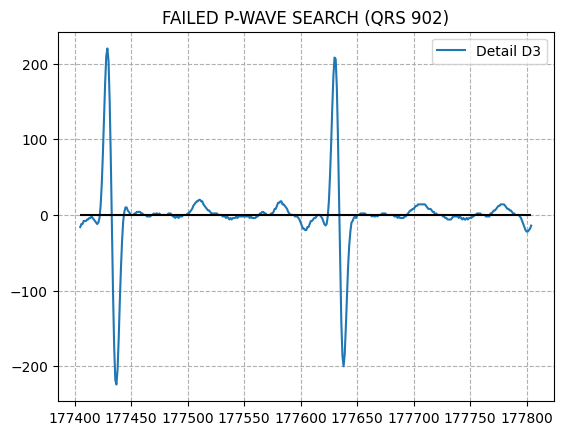

DEBUG: Failed to find P-wave for QRS at 179211


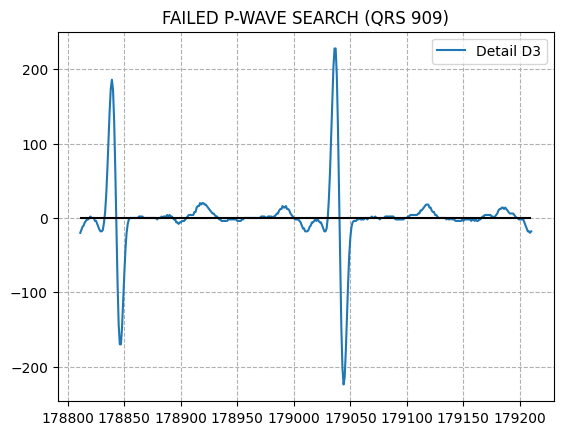

DEBUG: Failed to find P-wave for QRS at 183458


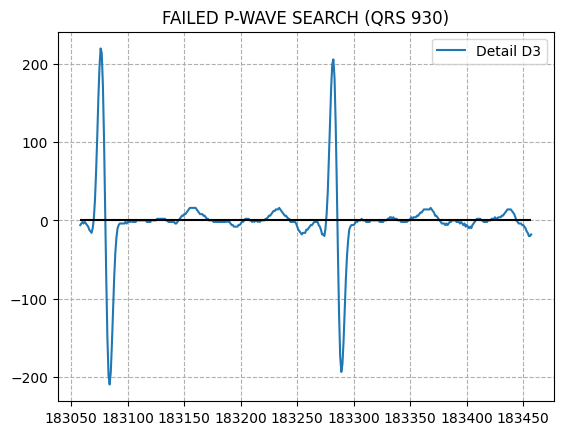

DEBUG: Failed to find P-wave for QRS at 186455


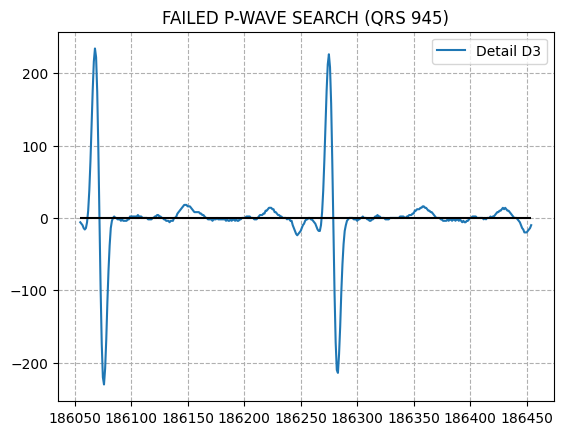

DEBUG: Failed to find P-wave for QRS at 187858


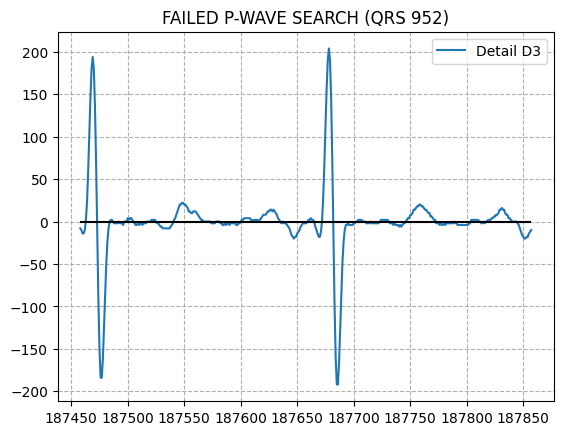

DEBUG: Failed to find P-wave for QRS at 190852


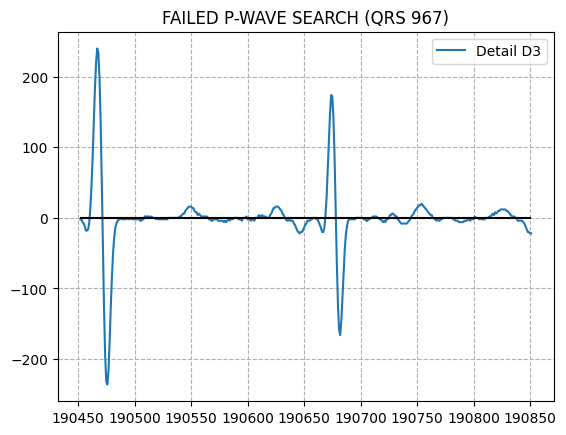

DEBUG: Failed to find P-wave for QRS at 191450


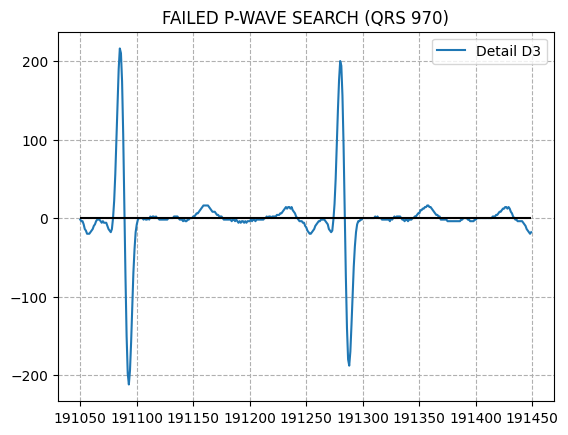

DEBUG: Failed to find P-wave for QRS at 195520


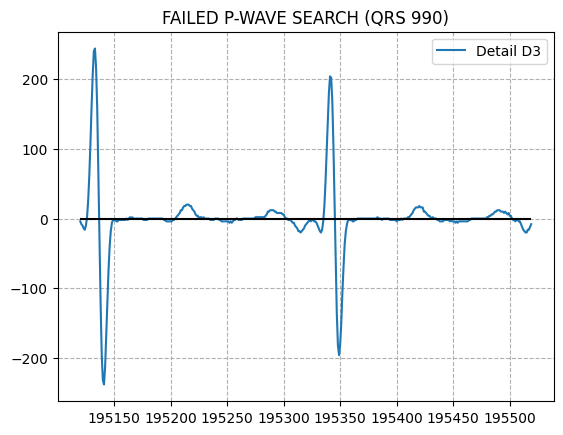

DEBUG: Failed to find P-wave for QRS at 198715


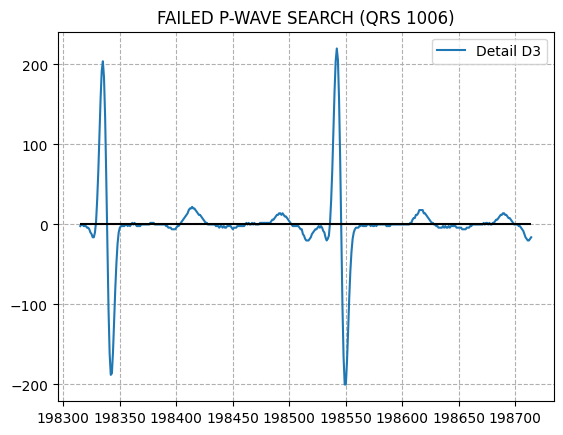

DEBUG: Failed to find P-wave for QRS at 200340


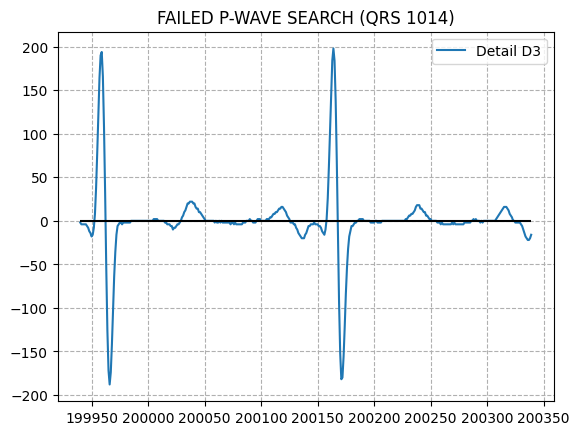

DEBUG: Failed to find P-wave for QRS at 202342


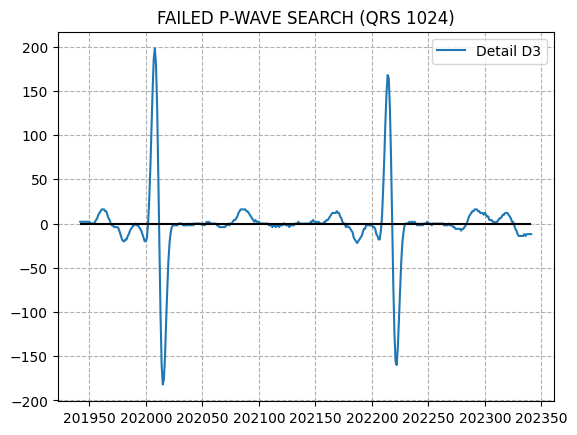

DEBUG: Failed to find P-wave for QRS at 202815


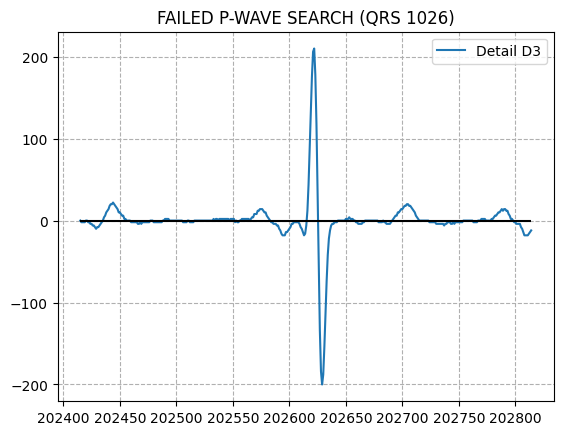

DEBUG: Failed to find P-wave for QRS at 203788


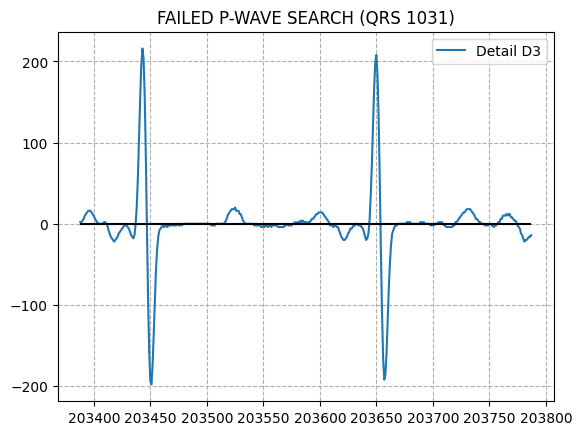

DEBUG: Failed to find P-wave for QRS at 204245


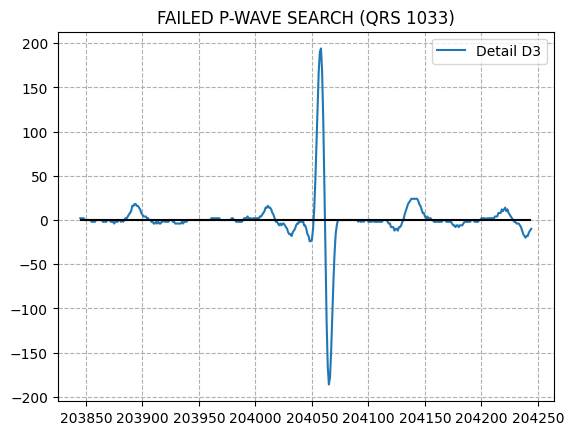

DEBUG: Failed to find P-wave for QRS at 205660


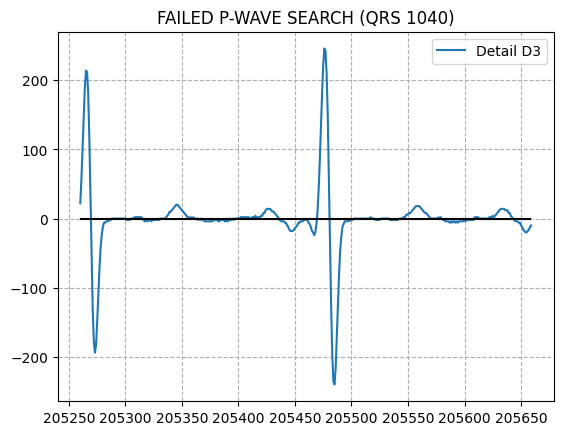

DEBUG: Failed to find P-wave for QRS at 208086


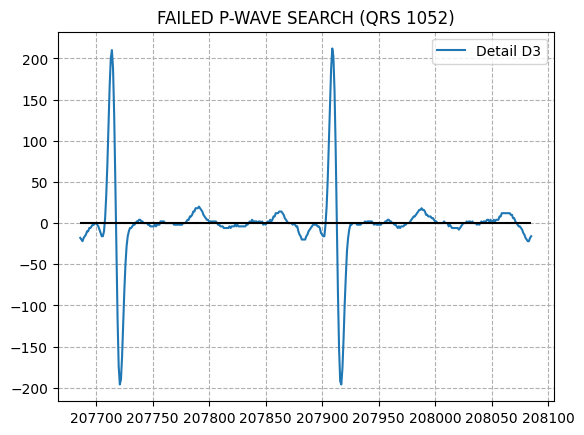

DEBUG: Failed to find P-wave for QRS at 208310


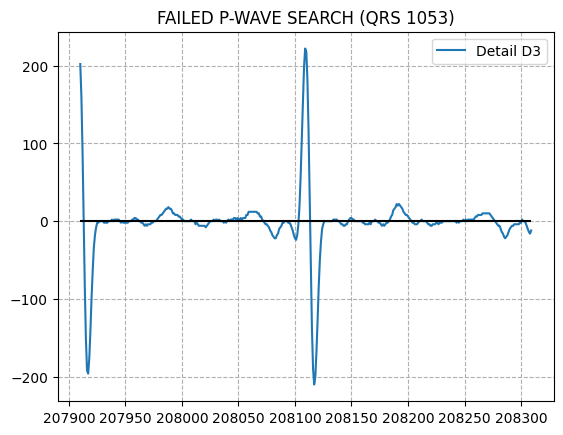

DEBUG: Failed to find P-wave for QRS at 213137


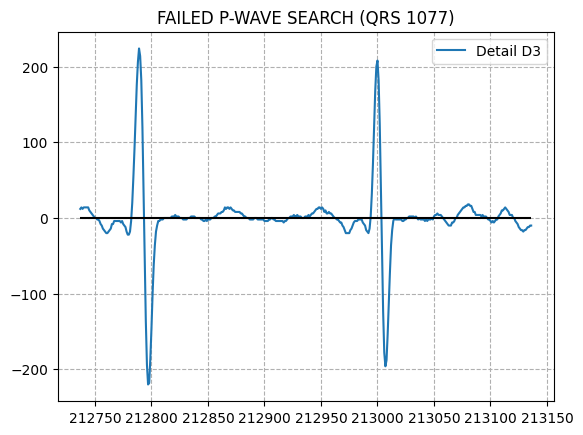

DEBUG: Failed to find P-wave for QRS at 215605


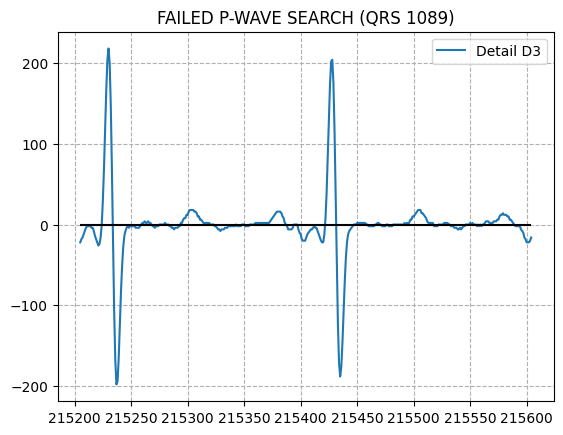

DEBUG: Failed to find P-wave for QRS at 216436


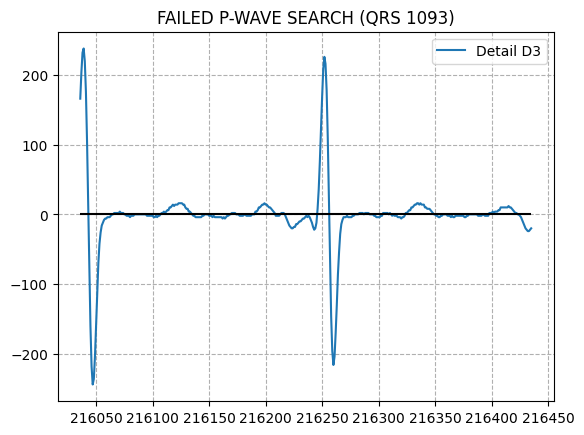

DEBUG: Failed to find P-wave for QRS at 216827


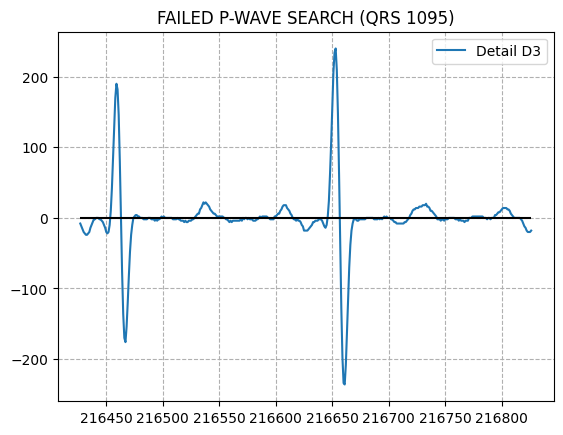

DEBUG: Failed to find P-wave for QRS at 220705


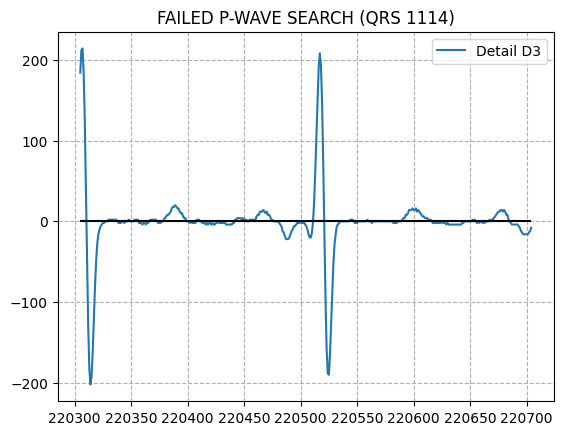

DEBUG: Failed to find P-wave for QRS at 221119


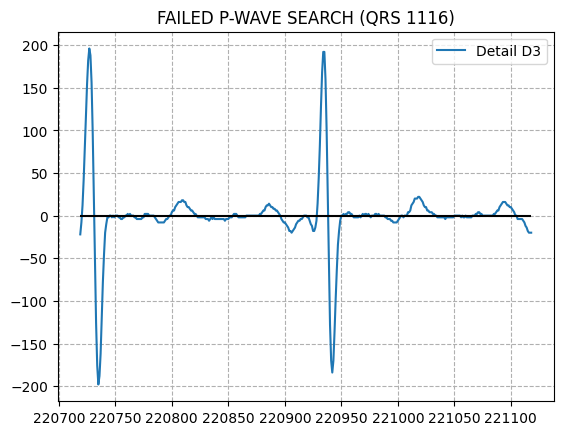

DEBUG: Failed to find P-wave for QRS at 221514


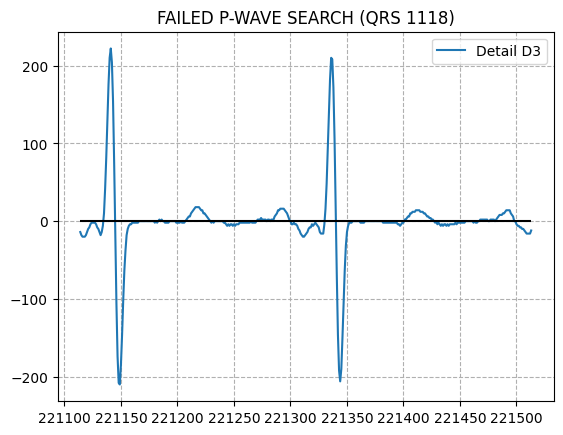

DEBUG: Failed to find P-wave for QRS at 224384


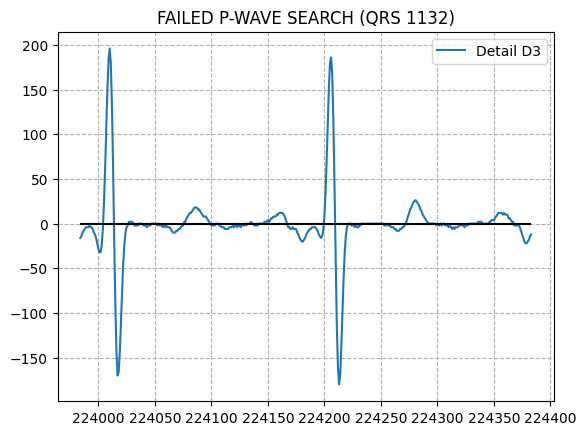

Number of QRS delineation succeded: 1135
Number of P-waves delineation succeded: 278


In [ ]:
def interbeat_interval(r_peaks, pos):
    """return half the samples distance between the actual R peak and the precedent"""
    if pos > 1 and pos < len(r_peaks):
        return np.right_shift(r_peaks[pos] - r_peaks[pos-1], 1)
    else:
        return np.inf
    
def biphasic_first_condition(d3, n_pre, n_post):
    """application of the (6.1) condition (from the paper) for a p_peak to be bi-phasic"""
    d3_n_post_mul2 = 2 * abs(d3[n_post])
    d3_n_post_div2 = np.right_shift(abs(d3[n_post]), 1)
    d3_n_pre = abs(d3[n_pre])

    if d3_n_post_div2 <= d3_n_pre and d3_n_pre <= d3_n_post_mul2:
        return True
    else:
        return False
    
def biphasic_second_condition(AMMp_P, AMMp_bi):
    """application of the (6.2) condition (from the paper) for a p_peak to be bi-phasic"""
    if AMMp_bi > np.right_shift(3 * AMMp_P, 2):
        return True
    else:
        return False


def P_wave_delineation(details, fs, QRS_onset, r_peaks):
    d3 = details[3]
    p_peaks = []
    p_onsets = []
    p_offsets = []
    max_window = int(fs * 0.3)  # 300 ms maximum window

    count = 0

    # find P wave
    for i_qrs, qrs_onset in enumerate(QRS_onset):
        ibi = interbeat_interval(r_peaks, i_qrs)
        fixed_window = min(ibi, max_window)
        zero_crossings = {}
        # save all the zc in the window
        for i in range(qrs_onset-fixed_window, qrs_onset):
            AMMp, left_peak_pos, right_peak_pos = is_zero_crossing(d3, i)
            if AMMp > 0:
                zero_crossings.update({i: {"AMMp": AMMp, "n_pre": left_peak_pos, "n_post": right_peak_pos}})
        # find P peak
        if len(zero_crossings) > 0: 
            p_peak_minpos = qrs_onset - fixed_window + 0.1*fs
            AMMp = 0
            p_peak = n_pre = n_post = None
            for zc, values in zero_crossings.items():
                if zc > p_peak_minpos and values["AMMp"] > AMMp:
                    p_peak = zc
                    n_pre = values["n_pre"]
                    n_post = values["n_post"]
                    AMMp = values["AMMp"]
            # if a P peak was found        
            if p_peak is not None:
                # Is it bi-phasic?
                if biphasic_first_condition(d3, n_pre, n_post):
                    # check if it is LEFT bi-phasic
                    # check if there is a zc max 100ms before the peak 
                    left_peak_window = range(int(p_peak - 0.1 * fs), p_peak)
                    for zc, values in zero_crossings.items():
                        if zc in left_peak_window and biphasic_first_condition(d3, values["n_pre"], values["n_post"]):
                            if biphasic_second_condition(AMMp, values["AMMp"]):
                                n_pre = values["n_pre"]
                    ## check if it is RIGHT bi-phasic
                    # check if there is a zc max 100ms before the peak 
                    right_peak_window = range(p_peak, int(p_peak + 0.1 * fs))
                    for zc, values in zero_crossings.items():
                        if zc in right_peak_window and biphasic_first_condition(d3, values["n_pre"], values["n_post"]):
                            if biphasic_second_condition(AMMp, values["AMMp"]):
                                n_post = values["n_post"]
                    
                    # find P onset
                    p_onset_min = qrs_onset-fixed_window
                    i = n_pre
                    thresh_onset = np.right_shift(abs(d3[n_pre]), 2)     # (6.3) threshold
                    candidate_onset = None
                    while i > p_onset_min and candidate_onset is None:
                        if abs(d3[i]) < thresh_onset:
                            candidate_onset = i
                        else:
                            i -= 1

                    # find P offset
                    p_offset_max = qrs_onset
                    i = n_post
                    thresh_offset = np.right_shift(abs(35*d3[n_post]), 6)    # (6.4) threshold
                    candidate_offset = None
                    while i < p_offset_max and candidate_offset is None:
                        if abs(d3[i]) < thresh_offset:
                            candidate_offset = i
                        else:
                            i += 1

                    if candidate_offset and candidate_onset:
                        p_peaks.append(p_peak)
                        p_onsets.append(candidate_onset)
                        p_offsets.append(candidate_offset)
                    else:
                        p_peaks.append(None)
                        p_onsets.append(None)
                        p_offsets.append(None)

                        # Inside the loop, if P-wave is NOT found:
                        print(f"DEBUG: Failed to find P-wave for QRS at {qrs_onset}")
                        if count < 3:
                            # Extract window for plotting
                            debug_win = range(qrs_onset - 400, qrs_onset) # Look 400 samples back
                            plt.figure()
                            plt.title(f"FAILED P-WAVE SEARCH (QRS {i_qrs})")
                            plt.plot(debug_win, d3[debug_win], label='Detail D3')
                            # Plot the threshold line to see if it was too high
                            plt.hlines(0, debug_win[0], debug_win[-1], colors='k')
                            plt.legend()
                            plt.grid(True, which='both', linestyle='--')
                            plt.show()
                            count += 1
            else:
                p_peaks.append(None)
                p_onsets.append(None)
                p_offsets.append(None)

    print(f"Number of QRS delineation succeded: {len(QRS_onset)}")
    print(f"Number of P-waves delineation succeded: {len(p_peaks)}")
    return p_peaks, p_onsets, p_offsets
            
p_peaks, p_onsets, p_offset = P_wave_delineation(details, fs, QRS_onset, r_peaks)

### T detection (mono & biphasic)